# Notebook 03 · Modèles de référence : de la règle de récence à la régression logistique

**Question.** Avant de sortir les arbres boosting (notebook 04), que valent les modèles « simples et interprétables » du cours ? On les compare tous avec **les mêmes 5 plis** (`c.get_folds()`), sur des prédictions **hors-échantillon** : règle de récence, score RFM, régression logistique (simple, Ridge, Lasso, ElasticNet, variables discrétisées), arbre de décision, k plus proches voisins, Naive Bayes. Le SVM est écarté (justifié en section 6).

**Plan.** 1. Cadrage · 2. Références sans modèle · 3. Régression logistique et odds ratios · 4. Arbre de décision · 5. k plus proches voisins · 6. Naive Bayes et SVM · 7. Comparaison · 8. Sauvegardes · 9. Limites et pistes.

*Lien avec le cours* : cette séquence suit la slide 51 (« Compare models » : régression logistique simple et interprétable, arbres, k-NN en référence, SVM et Naive Bayes en cas particuliers).

## 1. Cadrage de la modélisation

**Cible et fenêtre.** `repurchase = 1` si le client achète en **août 2020**. Chaque client est décrit au 1er août 2020 par des variables calculées uniquement sur les tickets antérieurs (notebook 02) : pas de fuite. Une seule coupure temporelle : les plis sont aléatoires et la saisonnalité n'est pas apprenable (slide 50 : périodes d'apprentissage et de test, saisonnalité, profondeur d'historique, fenêtre de calcul de la cible).

**Contrainte des 10 %.** Le marketing ne peut cibler que **10 % de la base** : seul compte le haut du classement. Le score sert à *ordonner* les clients ; la cible étant plus étroite que « acheter dans le mois », les probabilités ne sont pas des taux mensuels.

**Métriques retenues** (slides 71-72) :

| Métrique | Ce qu'elle dit | Pourquoi |
|---|---|---|
| **AUC** | probabilité qu'un racheteur ait un score plus élevé qu'un non-racheteur | métrique Kaggle ; ne dépend ni du seuil ni du taux de base |
| **Log-loss** | qualité des *probabilités* (calibration), pénalise la surconfiance | compare les modèles probabilistes ; sans objet pour une règle |
| **Précision, rappel, lift dans le top 10 %** | part de racheteurs parmi les 10 % ciblés, part des racheteurs captés, multiple du taux moyen | ce que la campagne obtiendra réellement |

**Pourquoi l'AUC seule ne suffit pas pour une campagne.** (i) L'AUC donne le même poids à tout le classement, alors que 90 % des clients ne seront jamais contactés : deux modèles de même AUC peuvent différer en tête de liste. (ii) Elle n'a pas d'unité métier : précision et lift se traduisent en euros, pas l'AUC. (iii) Elle ignore la calibration, nécessaire pour chiffrer un gain espéré (notebook 07). On lit donc les trois ensemble, avec la **stabilité entre plis** (slide 73).

**Stratégie de validation** (slides 66-69) : 5 plis **stratifiés** sur la cible, communs à tous les notebooks ; chaque client est prédit par un modèle qui ne l'a pas vu. Les hyperparamètres sont cherchés (grid ou random search) sur un **sous-échantillon stratifié de 40 000 clients**, puis le modèle retenu est évalué par la CV complète : la sélection d'hyperparamètres touche donc des clients qui se retrouvent ensuite en validation (optimisme léger, noté en limite). Le **test Kaggle** (40 106 clients sans cible) est le test final : jamais utilisé pour décider ; sa prédiction est la **moyenne des 5 modèles de plis**.

In [1]:
import os
for v in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[v] = '3'          # au plus 3 coeurs : d'autres notebooks tournent en parallèle
import sys, time, json, re, warnings
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import common as c

c.set_style()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 90)
N_JOBS = 3

def say(txt): display(Markdown(txt))
def fr(x, nd=2): return f'{x:,.{nd}f}'.replace(',', '\u202f').replace('.', ',')
def pc(x, nd=1): return fr(100 * x, nd) + ' %'

X = c.load_features('train'); Xte = c.load_features('test')
y = c.load_target().loc[X.index]; folds = c.get_folds().loc[X.index]
assert list(X.columns) == list(Xte.columns) and folds.index.equals(X.index)
CAT = list(X.select_dtypes(exclude='number').columns)
BIN = list(X.select_dtypes('int8').columns)
NUM = [k for k in X.columns if k not in CAT + BIN]
LOG = [k for k in NUM if k.startswith('log_')]
TWIN = [k[4:] for k in LOG]
NUM_RAW = [k for k in NUM if k not in LOG]                       # variables brutes
NUM_LOG = [k for k in NUM_RAW if k not in TWIN] + LOG            # jumeau log à la place de l'original
REF = {k: X[k].value_counts().idxmax() for k in CAT}             # modalité de référence = la plus fréquente
dico = pd.read_csv(c.RES / '02_feature_dictionary.csv').set_index('name')
n_na = int((X.isna().sum() > 0).sum())

say(f"**Données.** {fr(len(X), 0)} clients d'entraînement, {fr(len(Xte), 0)} de test ; {X.shape[1]} variables : "
    f"{len(NUM)} numériques ({len(LOG)} jumeaux `log_*`), {len(BIN)} binaires, {len(CAT)} qualitatives. "
    f"{n_na} colonnes contiennent des valeurs manquantes structurelles. Taux de rachat : **{pc(y.mean(), 2)}** "
    f"({fr(int(y.sum()), 0)} racheteurs). Contrainte : cibler {fr(c.TOP_FRAC * 100, 0)} % de la base, soit {fr(int(round(c.TOP_FRAC * len(X))), 0)} clients dans le train.")
tab_f = pd.DataFrame({'clients': folds.value_counts().sort_index(), 'racheteurs': y.groupby(folds).sum(), 'taux de rachat': y.groupby(folds).mean().round(4)})
tab_f.index.name = 'pli'; display(tab_f)

**Données.** 160 424 clients d'entraînement, 40 106 de test ; 100 variables : 81 numériques (19 jumeaux `log_*`), 13 binaires, 6 qualitatives. 50 colonnes contiennent des valeurs manquantes structurelles. Taux de rachat : **7,72 %** (12 392 racheteurs). Contrainte : cibler 10 % de la base, soit 16 042 clients dans le train.

,clients,racheteurs,taux de rachat
pli,,,
0,32085,2478,0.0772
1,32085,2478,0.0772
2,32085,2479,0.0773
3,32085,2479,0.0773
4,32084,2478,0.0772


In [2]:
# ---- Outillage commun : CV sur les 5 plis, enregistrement des résultats et des prédictions
from sklearn.metrics import roc_auc_score
ROWS, OOF, TEST, FOLD_AUC = [], {}, {}, {}

def run_cv(make_model):
    """Ajuste make_model() sur 4 plis, prédit le 5e (hors-échantillon) et le test. Retourne oof, test (moyenne des 5 plis), secondes, modèles."""
    oof = pd.Series(np.nan, index=X.index); te = np.zeros(len(Xte)); secs = 0.0; models = []
    for k in range(c.N_FOLDS):
        tr = (folds != k).values
        m = make_model(); t0 = time.time(); m.fit(X.loc[tr], y[tr]); secs += time.time() - t0
        oof[~tr] = m.predict_proba(X.loc[~tr])[:, 1]; te += m.predict_proba(Xte)[:, 1] / c.N_FOLDS
        models.append(m)
    return oof, pd.Series(te, index=Xte.index), secs, models

def fold_aucs(oof): return [roc_auc_score(y[folds == k], oof[folds == k]) for k in range(c.N_FOLDS)]

def register(name, family, params, interp, remark, oof, te, secs, proba=True):
    r = c.cv_report(y, oof, folds)
    if not proba: r['logloss'] = np.nan            # score non probabiliste : log-loss sans objet
    ROWS.append({'model': name, 'family': family, 'params': params, **r, 'fit_seconds': round(secs, 1),
                 'interpretability': interp, 'remark': remark})
    OOF[name], TEST[name], FOLD_AUC[name] = oof, te, fold_aucs(oof)
    c.save_predictions(name, oof, te)
    return pd.DataFrame(ROWS[-1:]).set_index('model')[['auc', 'auc_fold_mean', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10', 'fit_seconds']].round(4)

## 2. Références « sans modèle »

Un modèle ne vaut que par ce qu'il apporte **au-delà** de règles que n'importe quel marketeur appliquerait déjà. Deux références, sans aucun paramètre appris sur la cible :

- **Règle de récence** : score = −récence (les clients qui ont acheté le plus récemment en premier). Un client sans aucun achat reçoit le score le plus bas. On l'écrit `1/(1+récence)`, transformation monotone qui ne change pas le classement.
- **Score RFM simple** : quintiles de Récence, Fréquence (tickets sur 12 mois) et Montant (dépense sur 12 mois), score = (6 − R) + F + M, de 3 à 15 ; seuils appris sur le train, appliqués tels quels au test.

*Lien avec le cours* : RFM par quantiles (slides 23-28). Comme rien n'est ajusté sur la cible, ces scores sont « hors-échantillon » par construction ; la CV ne sert qu'à mesurer la stabilité entre plis. Leur log-loss n'a pas de sens (ce ne sont pas des probabilités).

In [3]:
worst = X['recency_days'].max() + 1
def rec_score(D): return (1 / (1 + D['recency_days'])).fillna(0.0)
r1 = register('recency_rule', 'Règle (sans modèle)', 'score = 1/(1+récence en jours)', 'Très élevée',
              'Référence à battre ; beaucoup d\'ex-aequo (récence en jours entiers)', rec_score(X), rec_score(Xte), 0.0, proba=False)

RFM = ['recency_days', 'n_tickets_all', 'spend_all']
edges = {k: np.nanquantile(X[k], [.2, .4, .6, .8]) for k in RFM}
def quint(D, k): return np.digitize(D[k].values, edges[k], right=True) + 1        # 1..5 ; NaN -> 5
def rfm_score(D):
    return pd.Series((6 - quint(D, 'recency_days')) + quint(D, 'n_tickets_all') + quint(D, 'spend_all'), index=D.index, dtype=float)
s_rfm = rfm_score(X)
r2 = register('rfm_score', 'Règle (sans modèle)', 'score = (6-R)+F+M, quintiles du train', 'Très élevée',
              'Score RFM du cours ; 13 valeurs distinctes seulement', s_rfm, rfm_score(Xte), 0.0, proba=False)
display(pd.concat([r1, r2]))
k10 = int(round(c.TOP_FRAC * len(X))); thr = np.sort(s_rfm.values)[::-1][k10 - 1]
say(f"**Lecture.** La seule récence classe à **{fr(r1.loc['recency_rule', 'auc'], 3)}** d'AUC ; dans le top 10 %, **{pc(r1.loc['recency_rule', 'precision_top10'])}** des clients ciblés rachètent "
    f"(lift {fr(r1.loc['recency_rule', 'lift_top10'])}). Le RFM complet fait **{fr(r2.loc['rfm_score', 'auc'], 3)}** d'AUC, mais ne prend que {s_rfm.nunique()} valeurs : {fr(int((s_rfm == thr).sum()), 0)} clients sont ex-aequo à la valeur de coupure du top 10 % "
    f"(départagés par l'ordre des identifiants, donc arbitrairement). C'est le plancher que les modèles doivent dépasser.")

,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
recency_rule,0.8180,0.8180,0.0035,NaN,0.2348,0.3039,3.0391,0.0
rfm_score,0.8407,0.8407,0.0030,NaN,0.3270,0.4233,4.2335,0.0


**Lecture.** La seule récence classe à **0,818** d'AUC ; dans le top 10 %, **23,5 %** des clients ciblés rachètent (lift 3,04). Le RFM complet fait **0,841** d'AUC, mais ne prend que 13 valeurs : 11 400 clients sont ex-aequo à la valeur de coupure du top 10 % (départagés par l'ordre des identifiants, donc arbitrairement). C'est le plancher que les modèles doivent dépasser.

## 3. Régression logistique : le modèle de référence interprétable

La logistique (slide 54) modélise la **cote** de rachat comme une combinaison linéaire des variables : chaque coefficient devient un **odds ratio** lisible par un marketeur. Ses limites annoncées par le cours : linéarité dans le log-odds, sensibilité aux valeurs extrêmes (déjà plafonnées au notebook 02) et à la colinéarité (d'où Ridge, Lasso, ElasticNet, slide 55).

### 3.1 Pipeline de préparation (slides 85-88)

Un seul `Pipeline` scikit-learn, ré-ajusté dans chaque pli (aucune information du pli de validation) :
- **numériques** : imputation par la **médiane** (les manquants sont structurels et les indicateurs `is_one_shot`, `has_interval_std`, `has_card`… sont déjà fournis), puis **standardisation** (coefficients comparables, pénalités équitables) ;
- **binaires** (0/1) : laissées telles quelles, l'odds ratio est celui de « 1 contre 0 » ;
- **qualitatives** : **one-hot N−1**, la modalité de référence étant la plus fréquente (lecture plus parlante qu'un ordre alphabétique) ; une modalité inconnue vaut la référence ;
- **asymétrie** : 19 variables ont un jumeau `log_*` (log(1+x)). Les deux versions doublonnent : pour un modèle linéaire il faut **choisir** (garder les deux crée de la colinéarité parfaite entre un original et son jumeau). On compare brut / log / les deux sur la logistique sans pénalité.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, uniform

def linear_prep(num_cols):
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
        ('bin', 'passthrough', BIN),
        ('cat', OneHotEncoder(drop=[REF[k] for k in CAT], handle_unknown='ignore', sparse_output=False), CAT)])

def lin_pipe(num_cols, **kw):
    return Pipeline([('prep', linear_prep(num_cols)), ('clf', LogisticRegression(**kw))])

variants = {'brut (original seul)': NUM_RAW, 'log (jumeau à la place de l\'original)': NUM_LOG, 'les deux versions': NUM}
runs, rows = {}, []
for lab, cols in variants.items():
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        oof, te, secs, models = run_cv(lambda: lin_pipe(cols, C=np.inf, max_iter=3000))
    runs[lab] = (oof, te, secs)
    r = c.cv_report(y, oof, folds)
    rows.append({'variante': lab, 'colonnes numériques': len(cols), 'AUC': r['auc'], 'écart-type plis': r['auc_fold_std'],
                 'log-loss': r['logloss'], 'lift top 10 %': r['lift_top10'], 'avertissements': len(w)})
tab_v = pd.DataFrame(rows).set_index('variante'); display(tab_v.round(4))
fa = {k: np.array(fold_aucs(v[0])) for k, v in runs.items()}; k_raw, k_log = list(runs)[0], list(runs)[1]
wins = int((fa[k_log] > fa[k_raw]).sum())
d_log = tab_v.iloc[1]['AUC'] - tab_v.iloc[0]['AUC']; d_both = tab_v.iloc[2]['AUC'] - tab_v.iloc[1]['AUC']
NUM_LIN = NUM_LOG
say(f"**Choix : la version log.** Passer du brut au log gagne **{fr(d_log, 4)}** d'AUC : un gain faible, mais présent dans {wins} plis sur {c.N_FOLDS} (l'écart-type entre plis, {fr(tab_v.iloc[1]['écart-type plis'], 4)}, est commun aux deux variantes), et la log-loss s'améliore : "
    f"les variables de comptage et de montant, très asymétriques, ont un effet plus proche de la linéarité en échelle log. Garder les deux versions change l'AUC de {fr(d_both, 4)} seulement, "
    f"pour {len(LOG)} colonnes redondantes. On retient donc, pour **tous les modèles linéaires**, le jumeau log à la place de l'original ({len(NUM_LIN)} variables numériques). "
    f"Les arbres, eux, utiliseront les variables brutes (invariants aux transformations monotones).")

,colonnes numériques,AUC,écart-type plis,log-loss,lift top 10 %,avertissements
variante,,,,,,
brut (original seul),62,0.8702,0.0023,0.1957,5.0259,0
log (jumeau à la place de l'original),62,0.8711,0.0024,0.1951,5.0671,0
les deux versions,81,0.8712,0.0023,0.1949,5.0703,0


**Choix : la version log.** Passer du brut au log gagne **0,0008** d'AUC : un gain faible, mais présent dans 5 plis sur 5 (l'écart-type entre plis, 0,0024, est commun aux deux variantes), et la log-loss s'améliore : les variables de comptage et de montant, très asymétriques, ont un effet plus proche de la linéarité en échelle log. Garder les deux versions change l'AUC de 0,0001 seulement, pour 19 colonnes redondantes. On retient donc, pour **tous les modèles linéaires**, le jumeau log à la place de l'original (62 variables numériques). Les arbres, eux, utiliseront les variables brutes (invariants aux transformations monotones).

### 3.2 Régression logistique simple (sans pénalité)

La version « manuel » du cours : maximum de vraisemblance, sans régularisation. Elle sert de point de comparaison pour les versions pénalisées.

In [5]:
oof, te, secs = runs['log (jumeau à la place de l\'original)']
r = register('logreg', 'Régression logistique', 'sans pénalité, variables log, standardisées', 'Très élevée',
             'Odds ratios directs ; colinéarité entre fenêtres de comptage', oof, te, secs)
display(r)

,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
logreg,0.8711,0.8711,0.0024,0.1951,0.3914,0.5067,5.0671,5.5


### 3.3 Ridge, Lasso, ElasticNet : régler la pénalité

Les trois pénalités du cours (slide 55) : **Ridge** (λΣβ², rétrécit tout), **Lasso** (λΣ|β|, annule des coefficients : sélection de variables), **ElasticNet** (mélange). Dans scikit-learn, `C = 1/λ` : *plus C est petit, plus la pénalité est forte*. On règle `C` (et le ratio L1 pour ElasticNet) par **grid search** (Ridge, Lasso) et **random search** (ElasticNet) avec 5 plis sur un **sous-échantillon stratifié de 40 000 clients**, critère AUC (slide 69). Le meilleur réglage est ensuite évalué par la CV complète. Pour le Lasso on retient aussi la règle de **l'écart-type** : le C le plus pénalisé dont l'AUC reste à moins d'un écart-type (de la moyenne des plis) du meilleur, soit le modèle le plus parcimonieux « aussi bon » statistiquement.

Sous-échantillon de réglage : 40 000 clients, taux de rachat 7,72 %.

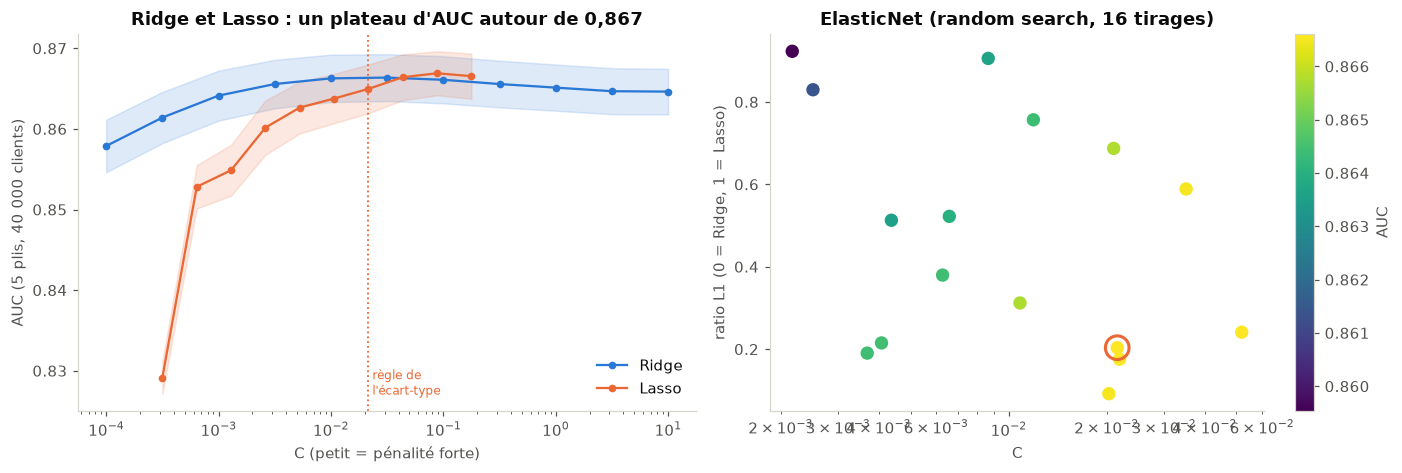

**Réglages retenus** (recherche en 108 s) : Ridge `C = 0.0316` ; Lasso `C = 0.088` (meilleur AUC) et `C = 0.0215` (règle de l'écart-type, parcimonieux) ; ElasticNet `C = 0.0215`, ratio L1 `0.20`. L'AUC est presque plate sur une large plage de C : le choix du réglage compte peu ici, ce qui rassure.

In [6]:
idx_sub, _ = train_test_split(X.index.values, train_size=40000, stratify=y.values, random_state=c.SEED)
Xs, ys = X.loc[idx_sub], y.loc[idx_sub]
cv_sub = StratifiedKFold(5, shuffle=True, random_state=c.SEED)
say(f"Sous-échantillon de réglage : {fr(len(Xs), 0)} clients, taux de rachat {pc(ys.mean(), 2)}.")

def search_table(g, pname):
    r = pd.DataFrame(g.cv_results_)
    out = r[[f'param_{pname}', 'mean_test_score', 'std_test_score']].copy()
    out.columns = ['C', 'auc', 'std']; out['se'] = out['std'] / np.sqrt(5)
    return out.sort_values('C').reset_index(drop=True)

t0 = time.time()
g_ridge = GridSearchCV(lin_pipe(NUM_LIN, l1_ratio=0.0, max_iter=3000), {'clf__C': np.logspace(-4, 1, 11)},
                       scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
g_lasso = GridSearchCV(lin_pipe(NUM_LIN, l1_ratio=1.0, solver='saga', max_iter=500, tol=1e-3), {'clf__C': np.logspace(-3.5, -0.75, 10)},
                       scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
g_enet = RandomizedSearchCV(lin_pipe(NUM_LIN, solver='saga', max_iter=500, tol=1e-3),
                            {'clf__C': loguniform(2e-3, 1e-1), 'clf__l1_ratio': uniform(0.05, 0.9)}, n_iter=16,
                            scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False, random_state=c.SEED).fit(Xs, ys)
t_search = time.time() - t0

tr_ = search_table(g_ridge, 'clf__C'); tl_ = search_table(g_lasso, 'clf__C')
C_ridge = tr_.loc[tr_['auc'].idxmax(), 'C']
ib = tl_['auc'].idxmax(); C_lasso = tl_.loc[ib, 'C']
C_1se = tl_.loc[(tl_['auc'] >= tl_.loc[ib, 'auc'] - tl_.loc[ib, 'se']), 'C'].min()
er = pd.DataFrame(g_enet.cv_results_); eb = er['mean_test_score'].idxmax()
C_enet, L1_enet = er.loc[eb, 'param_clf__C'], er.loc[eb, 'param_clf__l1_ratio']

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for t, lab, col in ((tr_, 'Ridge', c.BLUE), (tl_, 'Lasso', c.ACCENT)):
    ax[0].plot(t['C'], t['auc'], 'o-', color=col, label=lab, ms=4)
    ax[0].fill_between(t['C'], t['auc'] - t['se'], t['auc'] + t['se'], color=col, alpha=.15)
ax[0].axvline(C_1se, color=c.ACCENT, ls=':', lw=1.2); ax[0].text(C_1se, ax[0].get_ylim()[0] + .002, ' règle de\n l\'écart-type', color=c.ACCENT, fontsize=8)
ax[0].set_xscale('log'); ax[0].set_xlabel('C (petit = pénalité forte)'); ax[0].set_ylabel('AUC (5 plis, 40 000 clients)'); ax[0].legend(frameon=False)
ax[0].set_title(f'Ridge et Lasso : un plateau d\'AUC autour de {fr(max(tr_.auc.max(), tl_.auc.max()), 3)}')
sc_ = ax[1].scatter(er['param_clf__C'].astype(float), er['param_clf__l1_ratio'].astype(float), c=er['mean_test_score'], cmap='viridis', s=60)
ax[1].scatter([C_enet], [L1_enet], s=240, facecolors='none', edgecolors=c.ACCENT, lw=2)
ax[1].set_xscale('log'); ax[1].set_xlabel('C'); ax[1].set_ylabel('ratio L1 (0 = Ridge, 1 = Lasso)')
plt.colorbar(sc_, ax=ax[1], label='AUC'); ax[1].set_title('ElasticNet (random search, 16 tirages)')
fig.tight_layout(); c.save_fig(fig, '03_reglage_penalises'); plt.show()
say(f"**Réglages retenus** (recherche en {fr(t_search, 0)} s) : Ridge `C = {C_ridge:.3g}` ; Lasso `C = {C_lasso:.3g}` (meilleur AUC) et `C = {C_1se:.3g}` (règle de l'écart-type, parcimonieux) ; "
    f"ElasticNet `C = {C_enet:.3g}`, ratio L1 `{L1_enet:.2f}`. L'AUC est presque plate sur une large plage de C : le choix du réglage compte peu ici, ce qui rassure.")

In [7]:
def pen_fit(C, l1, solver):
    return lambda: lin_pipe(NUM_LIN, C=C, l1_ratio=l1, solver=solver, max_iter=3000, tol=1e-4)
def nz(models): return float(np.mean([(m[-1].coef_ != 0).sum() for m in models]))
ptot = len(linear_prep(NUM_LIN).fit(X.iloc[:2000]).get_feature_names_out())

oof, te, secs, m_ridge = run_cv(pen_fit(C_ridge, 0.0, 'lbfgs'))
r_ridge = register('logreg_ridge', 'Régression logistique pénalisée', f'L2 (Ridge), C={C_ridge:.3g}', 'Élevée',
                   'Coefficients rétrécis, aucun annulé', oof, te, secs)
oof, te, secs, m_lasso = run_cv(pen_fit(C_lasso, 1.0, 'saga'))
r_lasso = register('logreg_lasso', 'Régression logistique pénalisée', f'L1 (Lasso), C={C_lasso:.3g}', 'Élevée',
                   f'{nz(m_lasso):.0f} coefficients non nuls sur {ptot}', oof, te, secs)
oof, te, secs, m_1se = run_cv(pen_fit(C_1se, 1.0, 'saga'))
r_1se = register('logreg_lasso_1se', 'Régression logistique pénalisée', f'L1 (Lasso), C={C_1se:.3g} (règle de l\'écart-type)', 'Très élevée',
                 f'Parcimonieux : {nz(m_1se):.0f} coefficients non nuls sur {ptot}', oof, te, secs)
oof, te, secs, m_enet = run_cv(pen_fit(C_enet, L1_enet, 'saga'))
r_enet = register('logreg_enet', 'Régression logistique pénalisée', f'ElasticNet, C={C_enet:.3g}, l1_ratio={L1_enet:.2f}', 'Élevée',
                  f'{nz(m_enet):.0f} coefficients non nuls sur {ptot}', oof, te, secs)
display(pd.DataFrame(ROWS[-4:]).set_index('model')[['auc', 'auc_fold_std', 'logloss', 'lift_top10', 'fit_seconds', 'remark']].round(4))

,auc,auc_fold_std,logloss,lift_top10,fit_seconds,remark
model,,,,,,
logreg_ridge,0.8712,0.0024,0.1950,5.0687,9.7,"Coefficients rétrécis, aucun annulé"
logreg_lasso,0.8714,0.0024,0.1949,5.0905,151.0,91 coefficients non nuls sur 165
logreg_lasso_1se,0.8708,0.0024,0.1952,5.0615,108.1,Parcimonieux : 44 coefficients non nuls sur 165
logreg_enet,0.8713,0.0024,0.1949,5.0897,102.8,97 coefficients non nuls sur 165


### 3.4 Variables discrétisées en classes

Le cours cite la **discrétisation en classes** (slides 85-88). On découpe chaque variable numérique brute en **classes de quantiles** (le nombre de classes est réglé : 5 ou 10), puis one-hot N−1 : le modèle apprend alors **un effet par classe**, donc une forme libre (non linéaire, non monotone) par variable, et devient insensible aux valeurs extrêmes. Le coût : beaucoup plus de coefficients, et la perte de l'information à l'intérieur d'une classe. Avec des classes de quantiles, original et jumeau log donnent les mêmes classes : on part des variables brutes. Pénalité Ridge, `C` réglé avec le nombre de classes (grid search, 40 000 clients).

In [8]:
def binned_pipe(n_bins=10, C=0.1):
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('kb', KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile', quantile_method='averaged_inverted_cdf')),
                          ('oh', OneHotEncoder(drop='first', handle_unknown='ignore'))]), NUM_RAW),
        ('bin', 'passthrough', BIN),
        ('cat', OneHotEncoder(drop=[REF[k] for k in CAT], handle_unknown='ignore'), CAT)], sparse_threshold=1.0)
    return Pipeline([('prep', prep), ('clf', LogisticRegression(C=C, l1_ratio=0.0, max_iter=2000))])

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    g_bin = GridSearchCV(binned_pipe(), {'prep__num__kb__n_bins': [5, 10], 'clf__C': np.logspace(-2.5, -1, 4)},
                         scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
rb = pd.DataFrame(g_bin.cv_results_)
piv = rb.pivot(index='param_prep__num__kb__n_bins', columns='param_clf__C', values='mean_test_score')
piv.columns = [f'C={v:.3g}' for v in piv.columns]; piv.index.name = 'classes'
display(piv.round(4))
bb = rb['mean_test_score'].idxmax(); NB_BEST, C_BIN = int(rb.loc[bb, 'param_prep__num__kb__n_bins']), float(rb.loc[bb, 'param_clf__C'])
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    oof, te, secs, m_bin = run_cv(lambda: binned_pipe(NB_BEST, C_BIN))
n_coef = m_bin[0][-1].coef_.shape[1]
r_bin = register('logreg_binned', 'Régression logistique (variables discrétisées)', f'{NB_BEST} classes de quantiles, L2, C={C_BIN:.3g}', 'Élevée',
                 f'{n_coef} coefficients (un par classe) ; forme libre par variable', oof, te, secs)
display(r_bin)
gain_bin = r_bin.loc['logreg_binned', 'auc'] - r_ridge.loc['logreg_ridge', 'auc']
say(f"**Lecture.** Réglage retenu : {NB_BEST} classes, `C = {C_BIN:.3g}` ({n_coef} colonnes, réglage en {fr(time.time() - t0, 0)} s). Gain d'AUC sur la logistique Ridge à variables log : **{fr(gain_bin, 4)}** "
    f"(écart-type entre plis {fr(r_bin.loc['logreg_binned', 'auc_fold_std'], 4)}) : {'les classes ne font pas mieux que la forme linéaire en log' if gain_bin <= 0.0005 else 'la forme libre par variable apporte un petit gain'} : l'essentiel du signal est déjà bien capté par des effets monotones, et la perte d'information à l'intérieur des classes pèse autant que la souplesse gagnée.")

,C=0.00316,C=0.01,C=0.0316,C=0.1
classes,,,,
5,0.8617,0.8638,0.8640,0.8632
10,0.8617,0.8628,0.8625,0.8616


,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
logreg_binned,0.8695,0.8695,0.0029,0.1971,0.3912,0.5064,5.0639,17.5


**Lecture.** Réglage retenu : 5 classes, `C = 0.0316` (283 colonnes, réglage en 40 s). Gain d'AUC sur la logistique Ridge à variables log : **-0,0017** (écart-type entre plis 0,0029) : les classes ne font pas mieux que la forme linéaire en log : l'essentiel du signal est déjà bien capté par des effets monotones, et la perte d'information à l'intérieur des classes pèse autant que la souplesse gagnée.

### 3.5 Sélection de variables par le Lasso

Le Lasso annule les coefficients des variables redondantes (slide 55 : « automates variable selection »). Deux questions : combien de variables survivent, et lesquelles ? On regarde (a) le **chemin de régularisation** (quand chaque variable entre dans le modèle quand la pénalité se relâche) et (b) la **stabilité** de la sélection entre les 5 plis.

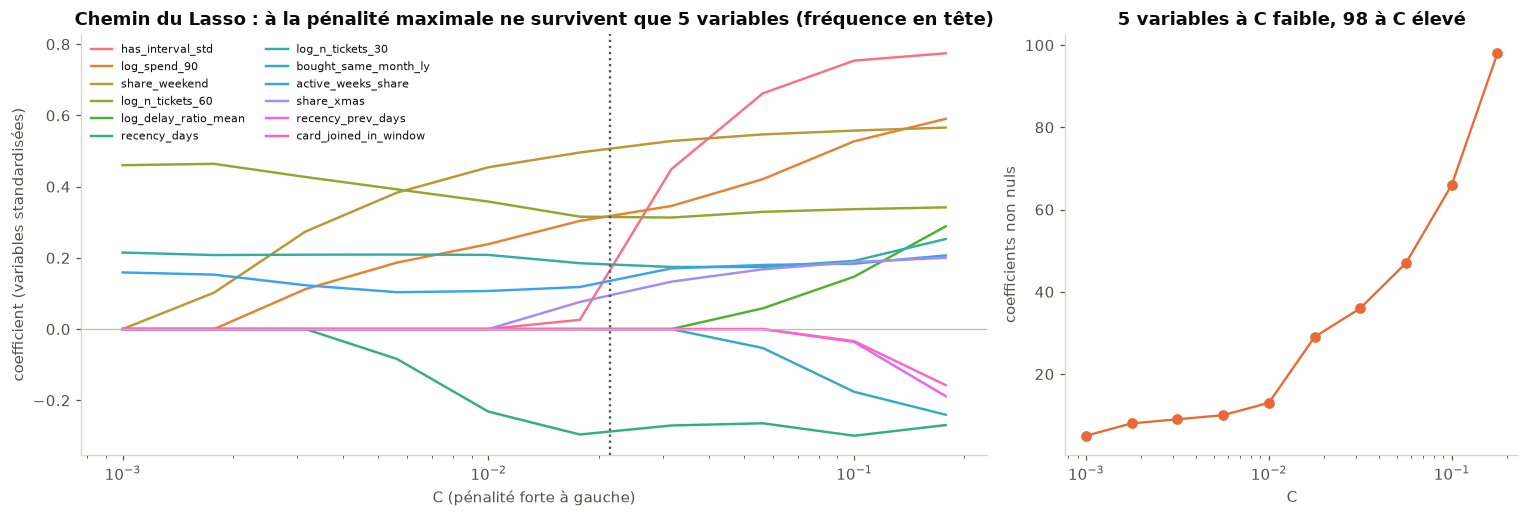

,colonnes,retenues (≥ 1 pli),retenues (5 plis sur 5)
Fréquence,9,8,8
Rythme et tendance,15,10,7
Saisonnalité,9,7,7
Promotions et retours,8,6,3
Montant,11,9,2
Paiement,6,3,2
Récence,4,2,1
Segment de prix,5,3,1
Magasins,35,4,0
Profil client,68,6,0


**Lecture.** Au réglage parcimonieux, le Lasso garde en moyenne **44 colonnes sur 165** (réglage de meilleure AUC : 91) ; 31 sont retenues dans les 5 plis. Les plus fortes (coefficient moyen en valeur absolue) : `share_weekend`, `has_interval_std`, `recency_days`, `log_n_tickets_180`, `log_n_tickets_60`, `log_spend_90`, `share_summer_months`, `log_n_tickets_all`. Familles les mieux représentées : Fréquence (8), Rythme et tendance (7), Saisonnalité (7).

In [9]:
def clean_names(prep): return [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
def base_of(n):
    if n in NUM or n in BIN: return n
    return max((k for k in CAT if n.startswith(k + '_')), key=len)
def fam_of(n): return dico.loc[base_of(n), 'group']

# (a) chemin de régularisation sur le sous-échantillon (démarrage à chaud)
prep_s = linear_prep(NUM_LIN).fit(Xs); Zs = prep_s.transform(Xs); names_s = clean_names(prep_s)
Cs = np.logspace(-3, -0.75, 10); path = []
lm = LogisticRegression(l1_ratio=1.0, solver='saga', warm_start=True, max_iter=500, tol=1e-3)
for Cv in Cs:
    lm.set_params(C=Cv); lm.fit(Zs, ys); path.append(lm.coef_[0].copy())
path = np.array(path); n_nz = (path != 0).sum(1)
top = np.argsort(-np.abs(path[-1]))[:12]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [2, 1]})
for j, col_ in zip(top, sns.color_palette('husl', len(top))): ax[0].plot(Cs, path[:, j], label=names_s[j], lw=1.6, color=col_)
ax[0].axhline(0, color=c.GREY, lw=.8); ax[0].axvline(C_1se, color=c.INK2, ls=':'); ax[0].set_xscale('log')
ax[0].set_xlabel('C (pénalité forte à gauche)'); ax[0].set_ylabel('coefficient (variables standardisées)'); ax[0].legend(fontsize=7, ncol=2, frameon=False)
first_vars = [names_s[j] for j in np.flatnonzero(path[0])]
ax[0].set_title(f'Chemin du Lasso : à la pénalité maximale ne survivent que {len(first_vars)} variables ({fam_of(first_vars[0]).lower()} en tête)')
ax[1].plot(Cs, n_nz, 'o-', color=c.ACCENT); ax[1].set_xscale('log'); ax[1].set_xlabel('C'); ax[1].set_ylabel('coefficients non nuls')
ax[1].set_title(f'{n_nz[0]} variables à C faible, {n_nz[-1]} à C élevé')
fig.tight_layout(); c.save_fig(fig, '03_lasso_chemin'); plt.show()

# (b) stabilité de la sélection entre plis (modèles parcimonieux, C de la règle de l'écart-type)
names_f = clean_names(m_1se[0][0]); coefs = np.array([m[-1].coef_[0] for m in m_1se])
sel_freq = pd.Series((coefs != 0).mean(0), index=names_f)
surv = pd.DataFrame({'variable': names_f, 'famille': [fam_of(n) for n in names_f], 'plis où retenue': (coefs != 0).sum(0),
                     'coef moyen': coefs.mean(0)}).query('`plis où retenue` > 0')
fam_tab = pd.DataFrame({'colonnes': pd.Series([fam_of(n) for n in names_f]).value_counts(),
                        'retenues (≥ 1 pli)': surv['famille'].value_counts(),
                        'retenues (5 plis sur 5)': surv.query('`plis où retenue` == 5')['famille'].value_counts()}).fillna(0).astype(int)
fam_tab = fam_tab.sort_values('retenues (5 plis sur 5)', ascending=False); display(fam_tab)
always = surv.query('`plis où retenue` == 5').sort_values('coef moyen', key=np.abs, ascending=False)
say(f"**Lecture.** Au réglage parcimonieux, le Lasso garde en moyenne **{nz(m_1se):.0f} colonnes sur {ptot}** (réglage de meilleure AUC : {nz(m_lasso):.0f}) ; "
    f"{len(always)} sont retenues dans les 5 plis. Les plus fortes (coefficient moyen en valeur absolue) : " + ', '.join(f'`{v}`' for v in always['variable'].head(8)) +
    f". Familles les mieux représentées : " + ', '.join(f'{i} ({r.iloc[2]})' for i, r in fam_tab.head(3).iterrows()) + '.')

### 3.6 Interpréter : les odds ratios d'un modèle parcimonieux

On part du **Lasso parcimonieux** (réglage de la règle de l'écart-type), ajusté sur tout le train, pour choisir les variables ; puis on **ré-ajuste une logistique sans pénalité** (statsmodels) sur ces seules variables, afin d'obtenir des odds ratios non rétrécis avec leur intervalle de confiance. Lecture :
- pour une variable **standardisée**, l'odds ratio est celui d'**un écart-type de plus** ; pour une variable log, un écart-type en échelle log correspond à multiplier (1 + x) par e^σ ;
- pour une **binaire ou une modalité** : « 1 contre 0 », ou « modalité contre référence » ;
- **toutes choses égales par ailleurs** : les variables de comptage sont très corrélées entre elles, leurs coefficients se lisent *ensemble* (une fenêtre peut compenser une autre) ;
- c'est une lecture **descriptive** : sélection et ré-ajustement utilisent les mêmes données, les intervalles sont un peu optimistes.

*Lien avec le cours* : odds ratios, slide 54 (« very interpretable (odds ratios) »).

,variable,famille,or_refit,ic95_bas,ic95_haut,or_lasso,p_value
1,share_weekend,Saisonnalité,1.794,1.742,1.847,1.765,0.000
2,log_spend_90,Montant,1.485,1.265,1.743,1.277,0.000
3,recency_days,Récence,0.712,0.607,0.835,0.689,0.000
4,log_n_tickets_30,Fréquence,1.332,1.227,1.445,1.200,0.000
5,share_summer_months,Saisonnalité,1.325,1.250,1.405,1.256,0.000
6,log_n_tickets_180,Fréquence,1.320,1.135,1.536,1.431,0.000
7,log_n_tickets_60,Fréquence,1.271,1.149,1.405,1.277,0.000
8,log_delay_ratio_mean,Rythme et tendance,1.233,1.129,1.346,1.034,0.000
9,is_one_shot,Rythme et tendance,0.572,0.434,0.753,0.834,0.000
10,has_interval_std,Rythme et tendance,1.598,1.299,1.965,1.581,0.000


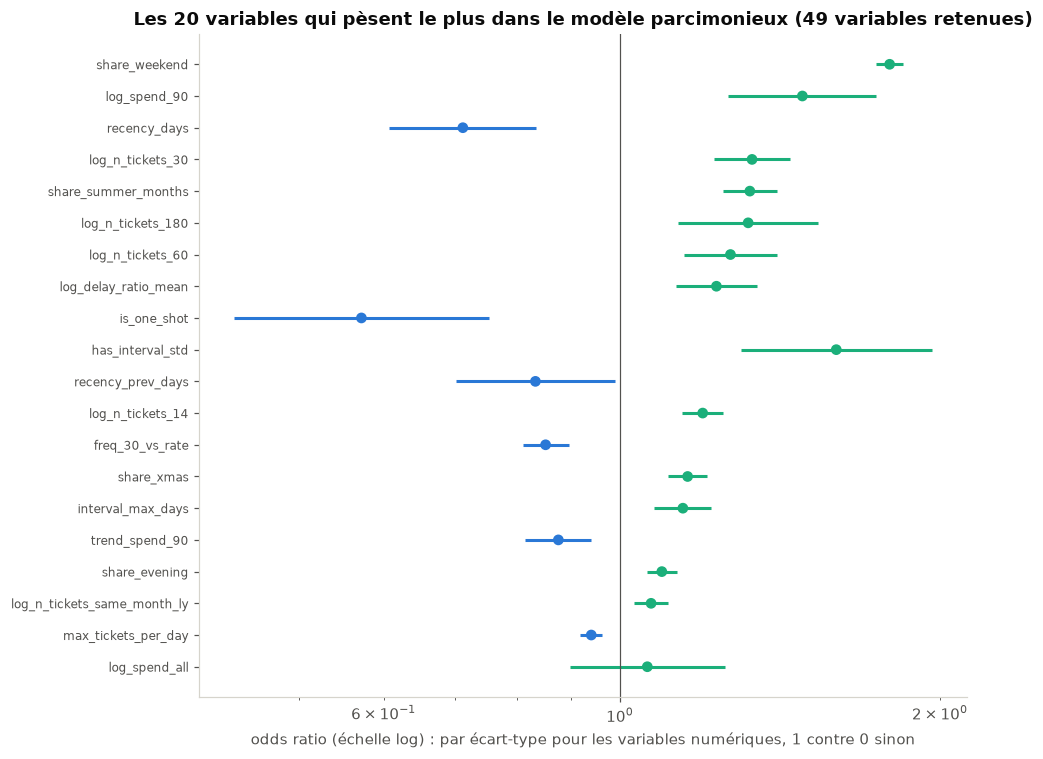

**Précautions.** Parmi ces variables numériques, la corrélation absolue maximale entre deux d'entre elles atteint **0,92** : les coefficients des fenêtres de comptage (`log_n_tickets_*`) se compensent et ne se lisent pas isolément. Lecture variable par variable, d'après le tableau :

- **1. `share_weekend`** : +1 écart-type de « Part des tickets le samedi ou le dimanche » (σ = 0,27) multiplie la cote de rachat par 1,79
- **2. `log_spend_90`** : +1 écart-type de « log(1 + spend_90) (variable déjà plafonnée) » (σ = 2,72, soit (1 + x) × 15,26) multiplie la cote de rachat par 1,48
- **3. `recency_days`** : +1 écart-type de « Jours entre le dernier ticket d'achat et la date de référence » (σ = 109,64) divise la cote de rachat par 1,40
- **4. `log_n_tickets_30`** : +1 écart-type de « log(1 + n_tickets_30) (variable déjà plafonnée) » (σ = 0,76, soit (1 + x) × 2,13) multiplie la cote de rachat par 1,33
- **5. `share_summer_months`** : +1 écart-type de « Part des tickets en juillet et août (vacances d'été) » (σ = 0,26) multiplie la cote de rachat par 1,33
- **6. `log_n_tickets_180`** : +1 écart-type de « log(1 + n_tickets_180) (variable déjà plafonnée) » (σ = 1,23, soit (1 + x) × 3,43) multiplie la cote de rachat par 1,32
- **7. `log_n_tickets_60`** : +1 écart-type de « log(1 + n_tickets_60) (variable déjà plafonnée) » (σ = 0,96, soit (1 + x) × 2,60) multiplie la cote de rachat par 1,27
- **8. `log_delay_ratio_mean`** : +1 écart-type de « log(1 + delay_ratio_mean) (variable déjà plafonnée) » (σ = 1,15, soit (1 + x) × 3,14) multiplie la cote de rachat par 1,23
- **9. `is_one_shot`** : « Client avec au plus un ticket d'achat » (1 contre 0) divise la cote de rachat par 1,75
- **10. `has_interval_std`** : « Client avec au moins 3 tickets (écart-type des intervalles défini) » (1 contre 0) multiplie la cote de rachat par 1,60
- **11. `recency_prev_days`** : +1 écart-type de « Jours entre l'avant-dernier ticket et la date de référence » (σ = 99,87) divise la cote de rachat par 1,20
- **12. `log_n_tickets_14`** : +1 écart-type de « log(1 + n_tickets_14) (variable déjà plafonnée) » (σ = 0,55, soit (1 + x) × 1,73) multiplie la cote de rachat par 1,20
- **13. `freq_30_vs_rate`** : +1 écart-type de « Tickets des 30 derniers jours / rythme mensuel moyen du client » (σ = 0,90) divise la cote de rachat par 1,17
- **14. `share_xmas`** : +1 écart-type de « Part des tickets du 20 décembre au 4 janvier » (σ = 0,13) multiplie la cote de rachat par 1,16
- **15. `interval_max_days`** : +1 écart-type de « Plus long intervalle (jours) » (σ = 55,52) multiplie la cote de rachat par 1,15
- **16. `trend_spend_90`** : +1 écart-type de « Tendance de dépense : log[(dépense 90 derniers j + 1) / (dépense des 90 j précédents + 1)] » (σ = 2,40) divise la cote de rachat par 1,14
- **17. `share_evening`** : +1 écart-type de « Part des tickets à partir de 18 h » (σ = 0,27) multiplie la cote de rachat par 1,10
- **18. `log_n_tickets_same_month_ly`** : +1 écart-type de « log(1 + n_tickets_same_month_ly) (variable déjà plafonnée) » (σ = 0,81, soit (1 + x) × 2,25) multiplie la cote de rachat par 1,07
- **19. `max_tickets_per_day`** : +1 écart-type de « Nombre maximal de tickets le même jour » (σ = 0,66) divise la cote de rachat par 1,06
- **20. `log_spend_all`** : +1 écart-type de « log(1 + spend_all) (variable déjà plafonnée) » (σ = 1,74, soit (1 + x) × 5,70) multiplie la cote de rachat par 1,06 *(non significatif à 5 %)*

In [10]:
import statsmodels.api as sm
prep_f = linear_prep(NUM_LIN).fit(X); Zf = pd.DataFrame(prep_f.transform(X), columns=clean_names(prep_f), index=X.index)
lasso_full = LogisticRegression(C=C_1se, l1_ratio=1.0, solver='saga', max_iter=3000, tol=1e-4).fit(Zf, y)
coef_l = pd.Series(lasso_full.coef_[0], index=Zf.columns); sel = list(coef_l.index[coef_l != 0])
logit = sm.Logit(y, sm.add_constant(Zf[sel])).fit(disp=0, maxiter=200)
sd_col = Zf[sel].std()                                  # écart-type de la colonne transformée (1 pour les variables standardisées)
sc_num = dict(zip(NUM_LIN, prep_f.named_transformers_['num']['sc'].scale_))   # écart-type avant standardisation
ci = logit.conf_int().loc[sel]
odds = pd.DataFrame({'variable': sel, 'famille': [fam_of(n) for n in sel],
                     'type': ['numérique (par écart-type)' if n in NUM else ('binaire (1 contre 0)' if n in BIN else 'modalité (contre référence)') for n in sel],
                     'coef_lasso': coef_l[sel].values, 'or_lasso': np.exp(coef_l[sel].values),
                     'coef_refit': logit.params[sel].values, 'or_refit': np.exp(logit.params[sel].values),
                     'ic95_bas': np.exp(ci[0].values), 'ic95_haut': np.exp(ci[1].values), 'p_value': logit.pvalues[sel].values})
odds['poids'] = np.abs(odds['coef_refit'].values) * sd_col.values       # effet d'un écart-type de la colonne : échelle commune
odds['sigma'] = [sc_num.get(n, np.nan) for n in sel]
def reading(r):
    n, o = r['variable'], r['or_refit']; mult = f'multiplie la cote de rachat par {fr(o)}' if o >= 1 else f'divise la cote de rachat par {fr(1 / o)}'
    d = dico.loc[base_of(n), 'description']
    if n in NUM:
        ech = f', soit (1 + x) × {fr(np.exp(r["sigma"]))}' if n.startswith('log_') else ''
        return f'+1 écart-type de « {d} » (σ = {fr(r["sigma"])}{ech}) {mult}'
    if n in BIN: return f'« {d} » (1 contre 0) {mult}'
    k = base_of(n); lev = n[len(k) + 1:]
    return f'{k} = {lev} (contre {REF[k]}) {mult}'
odds['lecture'] = odds.apply(reading, axis=1)
odds = odds.sort_values('poids', ascending=False).reset_index(drop=True)
c.save_result('03_odds_ratios', odds.set_index('variable'))
TOPN = 20; od = odds.head(TOPN)
disp = od[['variable', 'famille', 'or_refit', 'ic95_bas', 'ic95_haut', 'or_lasso', 'p_value']].copy(); disp.index = range(1, len(disp) + 1)
display(disp.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(od))[::-1]
cols = [c.GREEN if v >= 1 else c.BLUE for v in od['or_refit']]
ax.hlines(yy, od['ic95_bas'], od['ic95_haut'], color=cols, lw=2); ax.scatter(od['or_refit'], yy, color=cols, zorder=3)
ax.axvline(1, color=c.INK2, lw=.8); ax.set_xscale('log'); ax.set_yticks(yy); ax.set_yticklabels(od['variable'], fontsize=8)
ax.set_xlabel('odds ratio (échelle log) : par écart-type pour les variables numériques, 1 contre 0 sinon')
ax.set_title(f'Les {TOPN} variables qui pèsent le plus dans le modèle parcimonieux ({len(sel)} variables retenues)')
fig.tight_layout(); c.save_fig(fig, '03_odds_ratios'); plt.show()
cm = Zf[[v for v in od['variable'] if v in NUM]].corr().abs(); cmv = cm.to_numpy(copy=True); np.fill_diagonal(cmv, 0)
say(f"**Précautions.** Parmi ces variables numériques, la corrélation absolue maximale entre deux d'entre elles atteint **{fr(cmv.max())}** : "
    "les coefficients des fenêtres de comptage (`log_n_tickets_*`) se compensent et ne se lisent pas isolément. Lecture variable par variable, d'après le tableau :")
say('\n'.join(f'- **{i + 1}. `{r.variable}`** : {r.lecture}' + ('' if r.p_value < 0.05 else ' *(non significatif à 5 %)*') for i, r in od.iterrows()))

## 4. Arbre de décision

L'arbre (slides 58-59) pose une suite de questions sur les variables pour séparer racheteurs et non-racheteurs ; ses atouts selon le cours : **lisible comme un jeu de règles**, **pas de standardisation**, qualitatives et numériques traitées ensemble, **non-linéarités** captées ; ses limites : **sur-apprentissage**, instabilité. Ici : variables **brutes** (un arbre est invariant aux transformations monotones : les jumeaux log ne servent à rien), valeurs manquantes traitées **nativement** par scikit-learn, qualitatives en one-hot complet. Les deux réglages qui contrôlent le sur-apprentissage : la **profondeur maximale** et la **taille minimale d'une feuille** (en part de l'échantillon, pour qu'elle garde le même sens sur 40 000 ou 128 000 clients).

### 4.1 Le sur-apprentissage, en une courbe

,feuille ≥ 0.10%,feuille ≥ 0.25%,feuille ≥ 0.50%,feuille ≥ 1.00%
profondeur,,,,
2,0.8223,0.8223,0.8223,0.8223
3,0.8470,0.8470,0.8471,0.8471
4,0.8536,0.8536,0.8536,0.8539
5,0.8559,0.8563,0.8561,0.8563
6,0.8557,0.8559,0.8549,0.8557
8,0.8391,0.8462,0.8505,0.8533
10,0.8080,0.8334,0.8430,0.8524


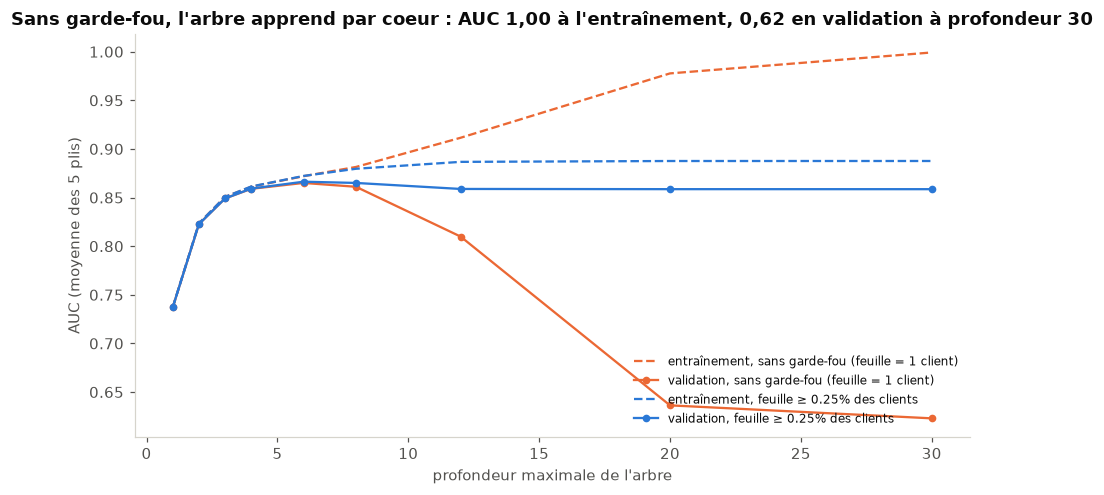

**Lecture.** Sans garde-fou, la validation culmine à **0,865** (profondeur 6) puis s'effondre à 0,623 à profondeur 30, alors que l'AUC d'entraînement monte à 0,999 : c'est le sur-apprentissage (slide 66). Imposer une taille minimale de feuille garde la validation stable (0,859 à profondeur 30). Réglage retenu par la recherche (en 166 s) : profondeur **5**, feuille ≥ **0.25%** de l'échantillon.

In [11]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from joblib import Parallel, delayed

def tree_prep():
    return ColumnTransformer([('num', 'passthrough', NUM_RAW), ('bin', 'passthrough', BIN),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
def tree_pipe(depth, leaf):
    return Pipeline([('prep', tree_prep()), ('clf', DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=c.SEED))])

# réglage (grid search, sous-échantillon de 40 000 clients)
t0 = time.time()
g_tree = GridSearchCV(tree_pipe(3, 0.01), {'clf__max_depth': [2, 3, 4, 5, 6, 8, 10], 'clf__min_samples_leaf': [0.001, 0.0025, 0.005, 0.01]},
                      scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
rt = pd.DataFrame(g_tree.cv_results_); bt = rt['mean_test_score'].idxmax()
D_TREE, LEAF_TREE = int(rt.loc[bt, 'param_clf__max_depth']), float(rt.loc[bt, 'param_clf__min_samples_leaf'])
piv_t = rt.pivot(index='param_clf__max_depth', columns='param_clf__min_samples_leaf', values='mean_test_score'); piv_t.index.name = 'profondeur'
piv_t.columns = [f'feuille ≥ {v:.2%}' for v in piv_t.columns]; display(piv_t.round(4))

# courbe train vs validation selon la profondeur (5 plis complets), sans garde-fou (feuille = 1 client) et avec la feuille retenue
Zt = tree_prep().fit_transform(X); yv = y.values; fv = folds.values
def _one(d, leaf, k):
    tr = fv != k; m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=c.SEED).fit(Zt[tr], yv[tr])
    return d, leaf, k, roc_auc_score(yv[tr], m.predict_proba(Zt[tr])[:, 1]), roc_auc_score(yv[~tr], m.predict_proba(Zt[~tr])[:, 1])
depths = [1, 2, 3, 4, 6, 8, 12, 20, 30]
res = Parallel(n_jobs=N_JOBS)(delayed(_one)(d, lf, k) for d in depths for lf in (1, LEAF_TREE) for k in range(c.N_FOLDS))
cur = pd.DataFrame(res, columns=['depth', 'leaf', 'fold', 'train', 'val']).groupby(['leaf', 'depth'])[['train', 'val']].mean().reset_index()
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for lf, col, lab in ((1, c.ACCENT, 'sans garde-fou (feuille = 1 client)'), (LEAF_TREE, c.BLUE, f'feuille ≥ {LEAF_TREE:.2%} des clients')):
    s_ = cur[cur.leaf == lf]
    ax.plot(s_.depth, s_.train, '--', color=col, label=f'entraînement, {lab}'); ax.plot(s_.depth, s_.val, '-o', color=col, ms=4, label=f'validation, {lab}')
ax.set_xlabel('profondeur maximale de l\'arbre'); ax.set_ylabel('AUC (moyenne des 5 plis)'); ax.legend(frameon=False, fontsize=8, loc='lower right')
s0 = cur[cur.leaf == 1]; dmax = s0.depth.max()
ax.set_title(f'Sans garde-fou, l\'arbre apprend par coeur : AUC {fr(s0.train.iloc[-1], 2)} à l\'entraînement, {fr(s0.val.iloc[-1], 2)} en validation à profondeur {dmax}')
fig.tight_layout(); c.save_fig(fig, '03_arbre_surapprentissage'); plt.show()
bv = s0.loc[s0.val.idxmax()]
say(f"**Lecture.** Sans garde-fou, la validation culmine à **{fr(bv.val, 3)}** (profondeur {int(bv.depth)}) puis s'effondre à {fr(s0.val.iloc[-1], 3)} à profondeur {dmax}, alors que l'AUC d'entraînement monte à {fr(s0.train.iloc[-1], 3)} : c'est le sur-apprentissage (slide 66). "
    f"Imposer une taille minimale de feuille garde la validation stable ({fr(cur[cur.leaf == LEAF_TREE].val.iloc[-1], 3)} à profondeur {dmax}). "
    f"Réglage retenu par la recherche (en {fr(time.time() - t0, 0)} s) : profondeur **{D_TREE}**, feuille ≥ **{LEAF_TREE:.2%}** de l'échantillon.")

In [12]:
oof, te, secs, m_tree = run_cv(lambda: tree_pipe(D_TREE, LEAF_TREE))
n_leaves = int(np.mean([m[-1].get_n_leaves() for m in m_tree]))
r_tree = register('tree', 'Arbre de décision', f'profondeur {D_TREE}, feuille ≥ {LEAF_TREE:.2%}', 'Très élevée',
                  f'~{n_leaves} feuilles ; scores par paliers (beaucoup d\'ex-aequo)', oof, te, secs)
display(r_tree)

,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
tree,0.864,0.8638,0.003,0.1986,0.3774,0.4886,4.8863,14.9


### 4.2 L'arbre lu comme un jeu de règles marketing

Pour la lecture, un arbre **peu profond** (profondeur 3, feuille ≥ 1 % des clients), ajusté sur tout le train : 8 règles au plus. Dans chaque case, la condition testée (« oui » à gauche, « non » à droite), le nombre de clients et leur taux de rachat observé ; la couleur suit le taux de rachat.

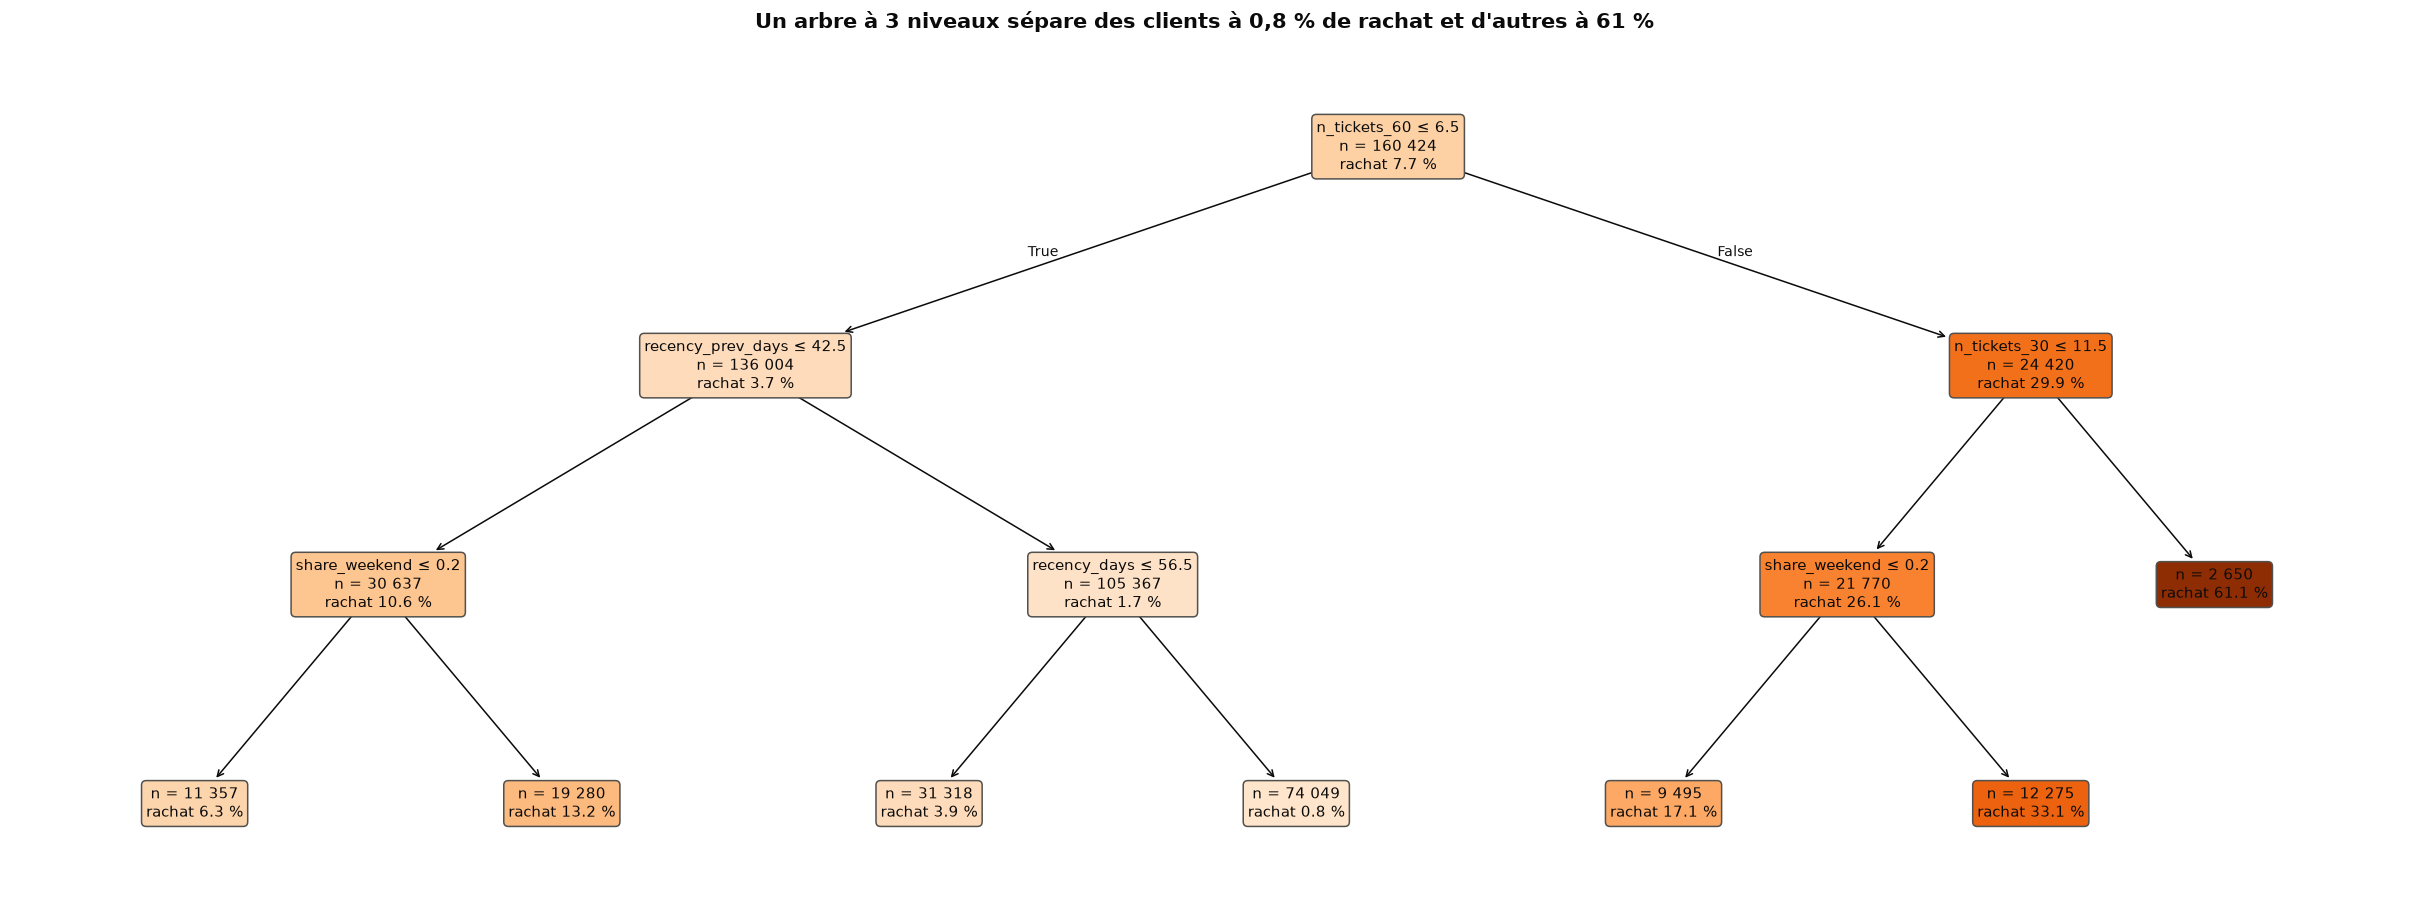

,règle (conditions successives),clients,part des clients (%),taux de rachat (%),lift
0,n_tickets_60 > 6.5 ET n_tickets_30 > 11.5,2650,1.7,61.1,7.91
1,n_tickets_60 > 6.5 ET n_tickets_30 ≤ 11.5 ET share_weekend > 0.2,12275,7.7,33.1,4.29
2,n_tickets_60 > 6.5 ET n_tickets_30 ≤ 11.5 ET share_weekend ≤ 0.2,9495,5.9,17.1,2.21
3,n_tickets_60 ≤ 6.5 ET recency_prev_days ≤ 42.5 ET share_weekend > 0.2,19280,12.0,13.2,1.71
4,n_tickets_60 ≤ 6.5 ET recency_prev_days ≤ 42.5 ET share_weekend ≤ 0.2,11357,7.1,6.3,0.81
5,n_tickets_60 ≤ 6.5 ET recency_prev_days > 42.5 ET recency_days ≤ 56.5,31318,19.5,3.9,0.50
6,n_tickets_60 ≤ 6.5 ET recency_prev_days > 42.5 ET recency_days > 56.5,74049,46.2,0.8,0.11


**Lecture.** Variables utilisées : `n_tickets_30`, `n_tickets_60`, `recency_days`, `recency_prev_days`, `share_weekend` (dont recency_days, recency_prev_days, share_weekend avec valeurs manquantes, acheminées nativement). La règle la plus favorable (rachat **61,1 %**, 2 650 clients, soit 1,7 % de la base) : *n_tickets_60 > 6.5 ET n_tickets_30 > 11.5*. À l'autre bout, 74 049 clients (46,2 % de la base) à 0,8 % : *n_tickets_60 ≤ 6.5 ET recency_prev_days > 42.5 ET recency_days > 56.5*. Ce petit arbre (7 feuilles, AUC en échantillon 0,849) donne un langage de segments directement actionnable, mais un score à 7 paliers ne peut pas cibler finement un top 10 %.

In [13]:
pre_t = tree_prep().fit(X); Zl = pre_t.transform(X); tn = clean_names(pre_t)
small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=0.01, random_state=c.SEED).fit(Zl, y)
T = small.tree_; dp = small.decision_path(Zl)
n_node = np.asarray(dp.sum(axis=0)).ravel(); pos_node = np.asarray(dp.T @ y.values).ravel(); rate = pos_node / n_node
used = sorted({tn[f] for f in T.feature if f >= 0}); used_nan = [u for u in used if u in X.columns and X[u].isna().any()]
def cond(i, left): return f'{tn[T.feature[i]]} {"≤" if left else ">"} {T.threshold[i]:.1f}'
rules, stack = [], [(0, [])]
while stack:
    i, path_ = stack.pop()
    if T.children_left[i] == -1:
        rules.append({'règle': ' ET '.join(path_) if path_ else '(tous)', 'clients': int(n_node[i]), 'part des clients': n_node[i] / len(X), 'taux de rachat': rate[i], 'lift': rate[i] / y.mean()})
    else:
        stack.append((T.children_right[i], path_ + [cond(i, False)])); stack.append((T.children_left[i], path_ + [cond(i, True)]))
rules = pd.DataFrame(rules).sort_values('taux de rachat', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(22, 8.5))
arts = plot_tree(small, feature_names=tn, filled=True, impurity=False, rounded=True, fontsize=9, ax=ax, precision=1)
arts = [a for a in arts if a.get_text().strip() not in ('True', 'False')]   # on écarte les étiquettes d'arête
assert len(arts) == T.node_count
cmap = plt.cm.Oranges
for i, a in enumerate(arts):
    head = f'{tn[T.feature[i]]} ≤ {T.threshold[i]:.1f}\n' if T.children_left[i] != -1 else ''
    a.set_text(f'{head}n = {n_node[i]:,}\nrachat {100 * rate[i]:.1f} %'.replace(',', ' ')); a.set_fontsize(10)
    a.get_bbox_patch().set_facecolor(cmap(min(0.12 + 1.6 * rate[i], 0.95))); a.get_bbox_patch().set_edgecolor(c.INK2)
ax.set_title(f'Un arbre à 3 niveaux sépare des clients à {fr(100 * rules["taux de rachat"].min(), 1)} % de rachat et d\'autres à {fr(100 * rules["taux de rachat"].max(), 0)} %', fontsize=14)
fig.tight_layout(); c.save_fig(fig, '03_arbre_lisible'); plt.show()
disp = rules.copy(); disp['part des clients'] = (100 * disp['part des clients']).round(1); disp['taux de rachat'] = (100 * disp['taux de rachat']).round(1); disp['lift'] = disp['lift'].round(2)
disp.columns = ['règle (conditions successives)', 'clients', 'part des clients (%)', 'taux de rachat (%)', 'lift']
display(disp)
auc_small = roc_auc_score(y, small.predict_proba(Zl)[:, 1])
say(f"**Lecture.** Variables utilisées : {', '.join('`' + u + '`' for u in used)}" + (f" (dont {', '.join(used_nan)} avec valeurs manquantes, acheminées nativement)" if used_nan else '') + ". "
    f"La règle la plus favorable (rachat **{pc(rules.loc[0, 'taux de rachat'])}**, {fr(rules.loc[0, 'clients'], 0)} clients, soit {pc(rules.loc[0, 'part des clients'])} de la base) : *{rules.loc[0, 'règle']}*. "
    f"À l'autre bout, {fr(rules.iloc[-1]['clients'], 0)} clients ({pc(rules.iloc[-1]['part des clients'])} de la base) à {pc(rules.iloc[-1]['taux de rachat'])} : *{rules.iloc[-1]['règle']}*. "
    f"Ce petit arbre ({len(rules)} feuilles, AUC en échantillon {fr(auc_small, 3)}) donne un langage de segments directement actionnable, mais un score à {len(rules)} paliers ne peut pas cibler finement un top 10 %.")

## 5. k plus proches voisins (la « référence » du cours)

Le k-NN (slide 51, « baseline ») ne fait aucun apprentissage : le score d'un client est le **taux de rachat de ses k plus proches voisins** dans l'espace des variables standardisées. Deux contraintes : il faut un **espace de petite dimension** (en grande dimension, les distances se ressemblent toutes) et le **calcul est lent** (chaque prédiction parcourt l'entraînement). On le restreint donc à **8 variables choisies a priori** pour ce qu'elles représentent (R, F, M et rythme : récence, fréquence sur 30 et 180 jours, mois actifs, régularité hebdomadaire, dépense, retard sur le rythme habituel, tendance), toutes parmi les plus informatives en AUC univariée au notebook 02 ; imputation médiane et standardisation comme plus haut. Réglage de k : grid search sur le sous-échantillon, puis **courbe sur les 5 plis complets** — le k optimal grandit avec la taille de l'échantillon, il faut donc le revérifier à pleine taille. Les prédictions sont instantanées sur 8 variables ; pas besoin de sous-échantillonner pour la CV finale.

variable,recency_days,log_n_tickets_30,log_n_tickets_180,n_active_months,active_weeks_share,log_spend_180,log_delay_ratio_mean,trend_freq_90
AUC univariée (notebook 02),0.818,0.837,0.846,0.803,0.833,0.822,0.7,0.586


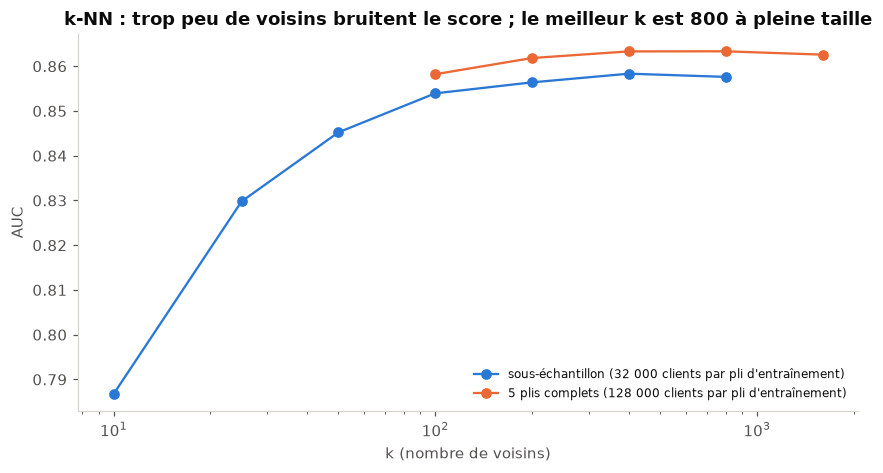

,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
knn,0.8633,0.8634,0.0025,0.2002,0.3764,0.4872,4.8726,0.9


**Lecture.** Meilleur k à pleine taille : **800** (AUC 0,863), contre 400 sur le sous-échantillon : l'optimum se déplace vers la droite avec la taille de l'échantillon. Un k aussi grand en fait un lissage très fort du taux de rachat local. **Limites.** (i) *Dimension* : avec les 62 variables numériques au lieu de 8 (pli 0 seul), l'AUC est de 0,868 contre 0,865 avec les 8 variables : la dimension ne pénalise pas ici, car ces variables sont très redondantes (la dimension effective reste faible), mais cela ne se généraliserait pas à des variables moins corrélées ; (ii) *vitesse* : prédire un pli prend de l'ordre de 5,0 s sur 8 variables mais 12 s sur 62 ; sur le test, chaque nouveau client doit être comparé à tout l'entraînement ; (iii) pas d'interprétation (aucun coefficient), pas de gestion native des qualitatives.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
KNN_VARS = ['recency_days', 'log_n_tickets_30', 'log_n_tickets_180', 'n_active_months', 'active_weeks_share', 'log_spend_180', 'log_delay_ratio_mean', 'trend_freq_90']
assert all(v in X.columns for v in KNN_VARS)
uni = pd.read_csv(c.RES / '02_univariate_auc.csv').set_index('name')['auc_signed']
tab_knn = pd.DataFrame({'variable': KNN_VARS, 'AUC univariée (notebook 02)': [uni.get(v, uni.get(v[4:], np.nan)) for v in KNN_VARS]}).set_index('variable')
display(tab_knn.round(3).T)

def knn_model(k, cols, n_jobs=1):
    return Pipeline([('cols', ColumnTransformer([('c', 'passthrough', cols)])), ('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=k, n_jobs=n_jobs))])

ks_sub = [10, 25, 50, 100, 200, 400, 800]
g_knn = GridSearchCV(knn_model(5, KNN_VARS), {'clf__n_neighbors': ks_sub}, scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
auc_sub = pd.Series(g_knn.cv_results_['mean_test_score'], index=ks_sub)
ks_full = [100, 200, 400, 800, 1600]; auc_full, t_full = {}, {}
for k in ks_full:
    oo = pd.Series(np.nan, index=X.index); t0 = time.time()
    for f in range(c.N_FOLDS):
        tr = (folds != f).values; m = knn_model(k, KNN_VARS, n_jobs=N_JOBS).fit(X.loc[tr], y[tr]); oo[~tr] = m.predict_proba(X.loc[~tr])[:, 1]
    auc_full[k] = roc_auc_score(y, oo); t_full[k] = time.time() - t0
auc_full = pd.Series(auc_full); K_BEST = int(auc_full.idxmax())
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(auc_sub.index, auc_sub.values, 'o-', color=c.BLUE, label='sous-échantillon (32 000 clients par pli d\'entraînement)')
ax.plot(auc_full.index, auc_full.values, 'o-', color=c.ACCENT, label='5 plis complets (128 000 clients par pli d\'entraînement)')
ax.set_xscale('log'); ax.set_xlabel('k (nombre de voisins)'); ax.set_ylabel('AUC'); ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.set_title(f'k-NN : trop peu de voisins bruitent le score ; le meilleur k est {K_BEST} à pleine taille')
fig.tight_layout(); c.save_fig(fig, '03_knn_k'); plt.show()
oof, te, secs, m_knn = run_cv(lambda: knn_model(K_BEST, KNN_VARS, n_jobs=N_JOBS))
r_knn = register('knn', 'k plus proches voisins', f'k={K_BEST}, 8 variables standardisées', 'Faible',
                 'Référence ; lent en prédiction ; sensible à la dimension', oof, te, secs)
display(r_knn)

# démonstration de la limite « dimension » : toutes les variables numériques, un seul pli
tr = (folds != 0).values; t0 = time.time()
m_hd = knn_model(K_BEST, NUM_LIN, n_jobs=N_JOBS).fit(X.loc[tr], y[tr]); p_hd = m_hd.predict_proba(X.loc[~tr])[:, 1]; t_hd = time.time() - t0
auc_hd = roc_auc_score(y[~tr], p_hd); auc_8 = roc_auc_score(y[~tr], OOF['knn'][~tr])
say(f"**Lecture.** Meilleur k à pleine taille : **{K_BEST}** (AUC {fr(auc_full.max(), 3)}), contre {int(auc_sub.idxmax())} sur le sous-échantillon{" : l'optimum se déplace vers la droite avec la taille de l'échantillon" if K_BEST > auc_sub.idxmax() else ""}. Un k aussi grand en fait un lissage très fort du taux de rachat local. "
    f"**Limites.** (i) *Dimension* : avec les {len(NUM_LIN)} variables numériques au lieu de 8 (pli 0 seul), l'AUC est de {fr(auc_hd, 3)} contre {fr(auc_8, 3)} avec les 8 variables : {'la dimension ne pénalise pas ici, car ces variables sont très redondantes (la dimension effective reste faible), mais cela ne se généraliserait pas à des variables moins corrélées' if auc_hd >= auc_8 else 'la dimension dégrade le score'} ; "
    f"(ii) *vitesse* : prédire un pli prend de l'ordre de {fr(t_full[K_BEST] / 5, 1)} s sur 8 variables mais {fr(t_hd, 0)} s sur {len(NUM_LIN)} ; sur le test, chaque nouveau client doit être comparé à tout l'entraînement ; "
    f"(iii) pas d'interprétation (aucun coefficient), pas de gestion native des qualitatives.")

## 6. Naive Bayes gaussien et SVM : les « cas particuliers »

**Naive Bayes** (slide 51) combine les variables en les supposant **indépendantes** conditionnellement à la cible, chacune suivant une loi normale par classe. Il est quasi instantané. Ici l'hypothèse d'indépendance est très fausse (les fenêtres de comptage sont fortement corrélées) : le classement peut rester correct, mais les probabilités sont extrêmes (log-loss mauvaise). On le teste sur deux jeux de variables : les 8 variables du k-NN et toutes les numériques (log) + binaires ; le lissage des variances (`var_smoothing`) est réglé par grid search.

**SVM : non entraîné.** Son coût d'apprentissage croît entre le carré et le cube du nombre de lignes : sur 128 000 clients par pli, plusieurs heures par pli pour un noyau non linéaire, sans probabilité native (slide 51 : « cas particuliers »). Un SVM linéaire n'apporterait pas mieux que la régression logistique, déjà testée.

In [16]:
from sklearn.naive_bayes import GaussianNB
def nb_model(cols, vs=1e-9):
    return Pipeline([('cols', ColumnTransformer([('c', 'passthrough', cols)])), ('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('clf', GaussianNB(var_smoothing=vs))])
NB_SETS = {'nb': (KNN_VARS, '8 variables (celles du k-NN)'), 'nb_all': (NUM_LIN + BIN, 'toutes les numériques log + binaires')}
nb_rows = []
for name, (cols, lab) in NB_SETS.items():
    g_nb = GridSearchCV(nb_model(cols), {'clf__var_smoothing': np.logspace(-9, -1, 9)}, scoring='roc_auc', cv=cv_sub, n_jobs=N_JOBS, refit=False).fit(Xs, ys)
    vs = float(g_nb.cv_results_['param_clf__var_smoothing'][int(np.argmax(g_nb.cv_results_['mean_test_score']))])
    oof, te, secs, _ = run_cv(lambda: nb_model(cols, vs))
    r = register(name, 'Naive Bayes gaussien', f'{lab}, var_smoothing={vs:.0e}', 'Moyenne',
                 'Indépendance irréaliste ; probabilités extrêmes ; très rapide', oof, te, secs)
    nb_rows.append(r)
display(pd.concat(nb_rows))

,auc,auc_fold_mean,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds
model,,,,,,,,
nb,0.8594,0.8594,0.0026,1.1047,0.3578,0.4632,4.6321,0.6
nb_all,0.8472,0.8472,0.0020,2.8818,0.3344,0.4329,4.3287,4.4


## 7. Comparaison des modèles

Tous les modèles sont évalués sur les **mêmes prédictions hors-échantillon** (5 plis). `fit_seconds` = temps d'ajustement cumulé des 5 plis (mesuré sur une machine partagée : indicatif).

In [17]:
table = pd.DataFrame(ROWS).sort_values('auc', ascending=False).reset_index(drop=True)
COLS = ['model', 'family', 'params', 'auc', 'auc_fold_mean', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10', 'fit_seconds', 'interpretability', 'remark']
table = table[COLS]; c.save_result('03_model_comparison', table.set_index('model'))
show = table[['model', 'auc', 'auc_fold_std', 'logloss', 'precision_top10', 'recall_top10', 'lift_top10', 'fit_seconds', 'interpretability']].copy()
show[['precision_top10', 'recall_top10']] = (100 * show[['precision_top10', 'recall_top10']]).round(1); display(show.set_index('model').round(4))
best = table.iloc[0]; BEST = best['model']; rec = table.set_index('model').loc['recency_rule']
lin = table[table.model.str.startswith('logreg')].iloc[0]
say(f"**Lecture.** Meilleur modèle de ce notebook (AUC hors-échantillon) : **`{BEST}`**, AUC **{fr(best.auc, 4)}**, précision {pc(best.precision_top10)} et rappel {pc(best.recall_top10)} dans le top 10 % (lift {fr(best.lift_top10)}), "
    f"contre {fr(rec.auc, 4)} et lift {fr(rec.lift_top10)} pour la seule récence : **+{fr(best.auc - rec.auc, 3)} d'AUC, +{fr(100 * (best.precision_top10 - rec.precision_top10))} points de précision** dans la cible. "
    f"Les modèles linéaires sont tous dans un mouchoir : écart d'AUC entre le meilleur et le pire des {len(table[table.model.str.startswith('logreg')])} modèles logistiques = {fr(table[table.model.str.startswith('logreg')].auc.max() - table[table.model.str.startswith('logreg')].auc.min(), 4)}, "
    f"à comparer à l'écart-type entre plis ({fr(best.auc_fold_std, 4)}) : à ce niveau, **le choix se fait sur l'interprétabilité**, pas sur l'AUC. "
    f"Le classement par AUC et celui par lift ne coïncident pas toujours : " + ', '.join(f'`{m}` ({i + 1}e AUC, {int(table.lift_top10.rank(ascending=False)[i])}e lift)' for i, m in enumerate(table.model) if i + 1 != int(table.lift_top10.rank(ascending=False)[i])) + '.')

,auc,auc_fold_std,logloss,precision_top10,recall_top10,lift_top10,fit_seconds,interpretability
model,,,,,,,,
logreg_lasso,0.8714,0.0024,0.1949,39.3,50.9,5.0905,151.0,Élevée
logreg_enet,0.8713,0.0024,0.1949,39.3,50.9,5.0897,102.8,Élevée
logreg_ridge,0.8712,0.0024,0.1950,39.2,50.7,5.0687,9.7,Élevée
logreg,0.8711,0.0024,0.1951,39.1,50.7,5.0671,5.5,Très élevée
logreg_lasso_1se,0.8708,0.0024,0.1952,39.1,50.6,5.0615,108.1,Très élevée
logreg_binned,0.8695,0.0029,0.1971,39.1,50.6,5.0639,17.5,Élevée
tree,0.8640,0.0030,0.1986,37.7,48.9,4.8863,14.9,Très élevée
knn,0.8633,0.0025,0.2002,37.6,48.7,4.8726,0.9,Faible
nb,0.8594,0.0026,1.1047,35.8,46.3,4.6321,0.6,Moyenne


**Lecture.** Meilleur modèle de ce notebook (AUC hors-échantillon) : **`logreg_lasso`**, AUC **0,8714**, précision 39,3 % et rappel 50,9 % dans le top 10 % (lift 5,09), contre 0,8180 et lift 3,04 pour la seule récence : **+0,053 d'AUC, +15,85 points de précision** dans la cible. Les modèles linéaires sont tous dans un mouchoir : écart d'AUC entre le meilleur et le pire des 6 modèles logistiques = 0,0019, à comparer à l'écart-type entre plis (0,0024) : à ce niveau, **le choix se fait sur l'interprétabilité**, pas sur l'AUC. Le classement par AUC et celui par lift ne coïncident pas toujours : `logreg_lasso_1se` (5e AUC, 6e lift), `logreg_binned` (6e AUC, 5e lift).

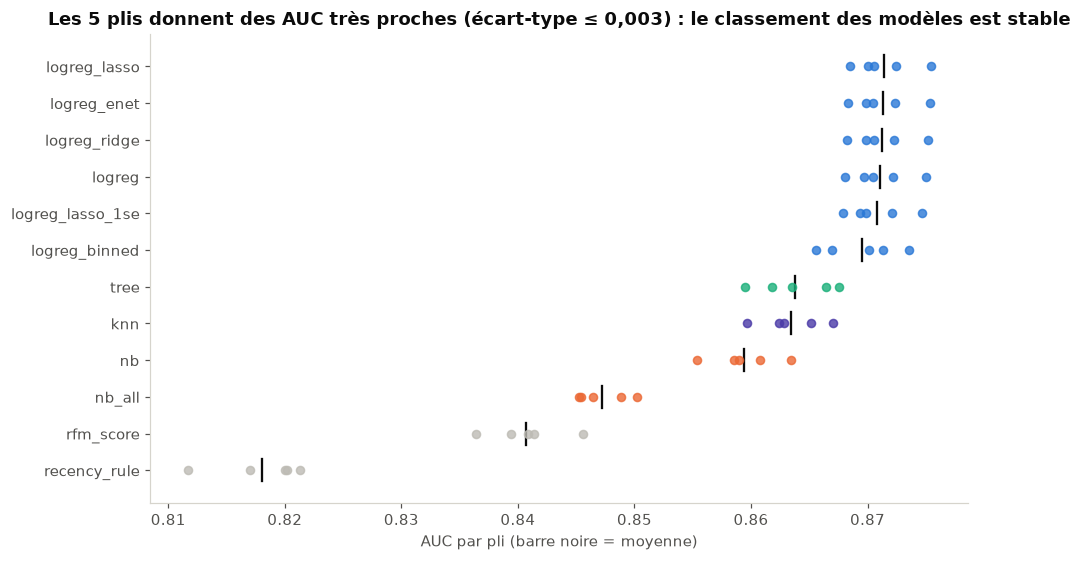

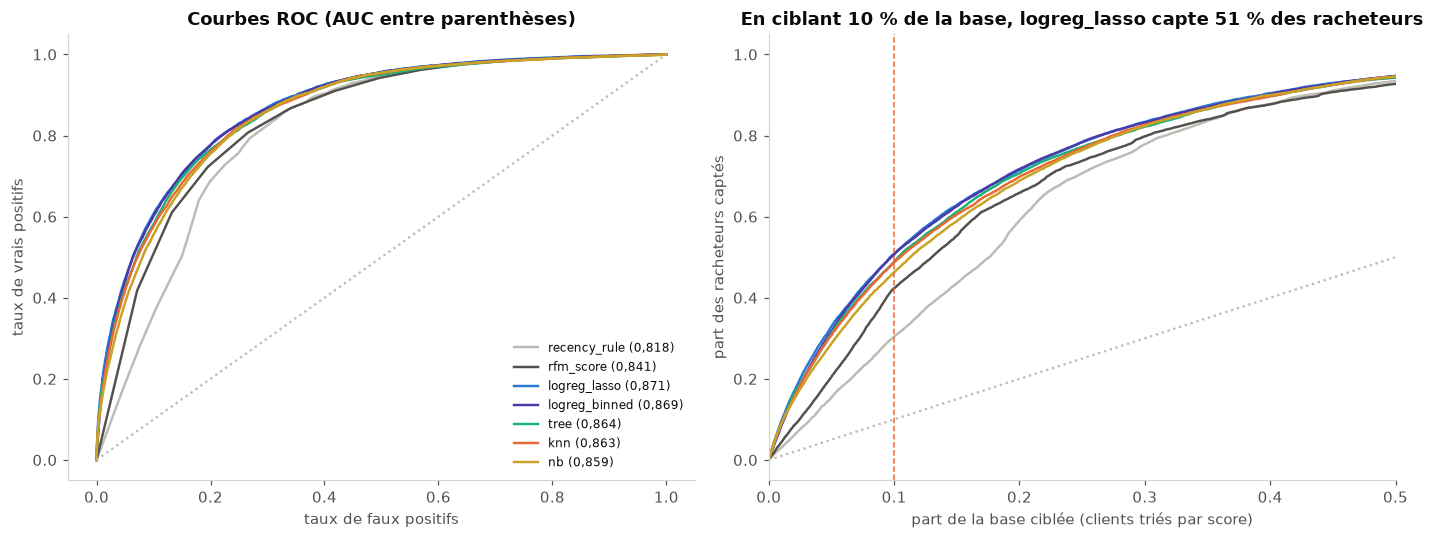

In [18]:
# --- stabilité entre plis
order = list(table.model[::-1]); fam_col = {'Règle (sans modèle)': c.GREY, 'Régression logistique': c.BLUE, 'Régression logistique pénalisée': c.BLUE,
                                           'Régression logistique (variables discrétisées)': c.BLUE, 'Arbre de décision': c.GREEN, 'k plus proches voisins': c.PURPLE, 'Naive Bayes gaussien': c.ACCENT}
fam_of_model = table.set_index('model')['family']
fig, ax = plt.subplots(figsize=(9, 5.2))
for i, m in enumerate(order):
    ax.scatter(FOLD_AUC[m], [i] * c.N_FOLDS, color=fam_col[fam_of_model[m]], s=28, alpha=.8, zorder=3)
    ax.plot([np.mean(FOLD_AUC[m])] * 2, [i - .3, i + .3], color=c.INK, lw=1.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel('AUC par pli (barre noire = moyenne)')
sd_max = max(np.std(v) for v in FOLD_AUC.values())
ax.set_title(f'Les 5 plis donnent des AUC très proches (écart-type ≤ {fr(sd_max, 3)}) : le classement des modèles est stable')
fig.tight_layout(); c.save_fig(fig, '03_auc_par_pli'); plt.show()

# --- ROC et gain cumulé
from sklearn.metrics import roc_curve
MAIN = ['recency_rule', 'rfm_score', lin['model'], 'logreg_binned', 'tree', 'knn', 'nb']
MAIN = list(dict.fromkeys(MAIN)); pal = [c.GREY, c.INK2, c.BLUE, c.PURPLE, c.GREEN, c.ACCENT, '#c9a227']
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for m, col in zip(MAIN, pal):
    s = OOF[m]; fpr, tpr, _ = roc_curve(y, s)
    ax[0].plot(fpr, tpr, color=col, label=f'{m} ({fr(table.set_index("model").loc[m, "auc"], 3)})', lw=1.6)
    o = np.argsort(-s.values, kind='stable'); gain = np.cumsum(y.values[o]) / y.sum(); xs = np.arange(1, len(o) + 1) / len(o)
    ax[1].plot(xs, gain, color=col, lw=1.6)
ax[0].plot([0, 1], [0, 1], color=c.GREY, ls=':'); ax[1].plot([0, 1], [0, 1], color=c.GREY, ls=':')
ax[0].set_xlabel('taux de faux positifs'); ax[0].set_ylabel('taux de vrais positifs'); ax[0].legend(frameon=False, fontsize=8, loc='lower right'); ax[0].set_title('Courbes ROC (AUC entre parenthèses)')
ax[1].axvline(c.TOP_FRAC, color=c.ACCENT, ls='--', lw=1); ax[1].set_xlabel('part de la base ciblée (clients triés par score)'); ax[1].set_ylabel('part des racheteurs captés')
ax[1].set_title(f'En ciblant 10 % de la base, {BEST} capte {pc(best.recall_top10, 0)} des racheteurs'); ax[1].set_xlim(0, .5)
fig.tight_layout(); c.save_fig(fig, '03_roc_gain'); plt.show()

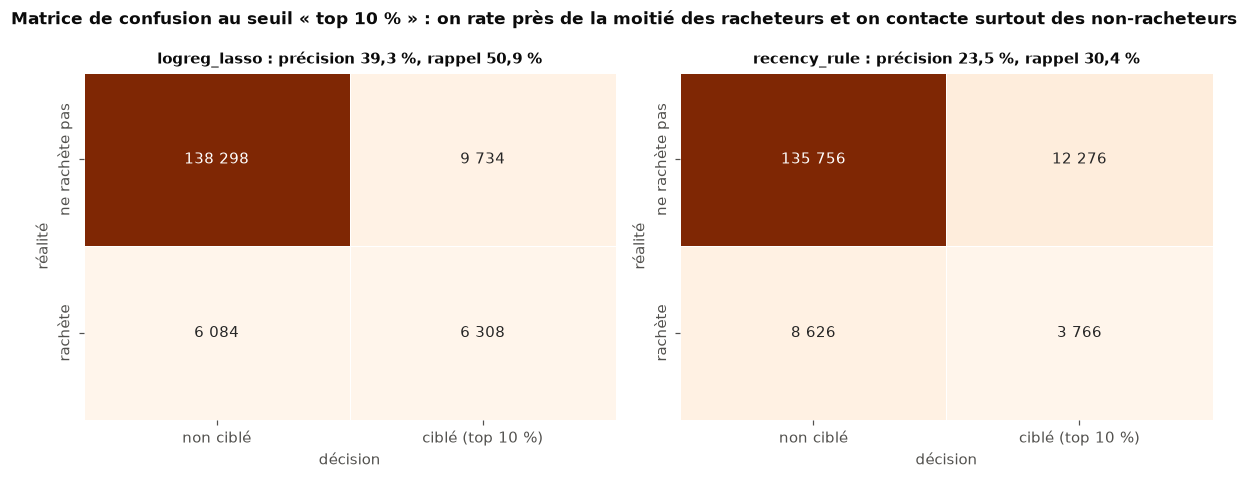

**Lecture** (`logreg_lasso`, seuil = score du 10 % supérieur) : précision 39,3 %, rappel 50,9 %, F1 0,444, exactitude 90,1 %. L'exactitude flatte (un modèle qui ne cible personne atteindrait 92,3 %) : c'est pourquoi on pilote la campagne avec précision, rappel et lift, pas avec l'exactitude. Dans la cible de 16 042 clients, 9 734 ne rachètent pas : c'est le coût d'un e-mail « perdu » que le notebook 07 chiffrera.

In [19]:
# --- matrice de confusion au seuil du top 10 %
def confusion(s):
    k = int(round(c.TOP_FRAC * len(s))); pred = np.zeros(len(s), bool); pred[np.argsort(-s.values, kind='stable')[:k]] = True; t = y.values == 1
    tp, fp, fn, tn_ = (pred & t).sum(), (pred & ~t).sum(), (~pred & t).sum(), (~pred & ~t).sum()
    P, R = tp / (tp + fp), tp / (tp + fn)
    return np.array([[tn_, fp], [fn, tp]]), {'précision': P, 'rappel': R, 'F1': 2 * P * R / (P + R), 'exactitude': (tp + tn_) / len(s)}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4)); cm_info = {}
for a, m in zip(ax, [BEST, 'recency_rule']):
    cmx, mt = confusion(OOF[m]); cm_info[m] = (cmx, mt)
    sns.heatmap(cmx, annot=np.array([[f'{v:,}'.replace(',', ' ') for v in r] for r in cmx]), fmt='', cmap='Oranges', cbar=False, ax=a, linewidths=.5,
                xticklabels=['non ciblé', 'ciblé (top 10 %)'], yticklabels=['ne rachète pas', 'rachète'])
    a.set_title(f'{m} : précision {pc(mt["précision"])}, rappel {pc(mt["rappel"])}', fontsize=10); a.set_xlabel('décision'); a.set_ylabel('réalité')
fig.suptitle('Matrice de confusion au seuil « top 10 % » : on rate près de la moitié des racheteurs et on contacte surtout des non-racheteurs', fontweight='bold', fontsize=11)
fig.tight_layout(); c.save_fig(fig, '03_matrice_confusion'); plt.show()
mt = cm_info[BEST][1]
say(f"**Lecture** (`{BEST}`, seuil = score du {fr(c.TOP_FRAC * 100, 0)} % supérieur) : précision {pc(mt['précision'])}, rappel {pc(mt['rappel'])}, F1 {fr(mt['F1'], 3)}, exactitude {pc(mt['exactitude'])}. "
    f"L'exactitude flatte (un modèle qui ne cible personne atteindrait {pc(1 - y.mean())}) : c'est pourquoi on pilote la campagne avec précision, rappel et lift, pas avec l'exactitude. "
    f"Dans la cible de {fr(cm_info[BEST][0][:, 1].sum(), 0)} clients, {fr(cm_info[BEST][0][0, 1], 0)} ne rachètent pas : c'est le coût d'un e-mail « perdu » que le notebook 07 chiffrera.")

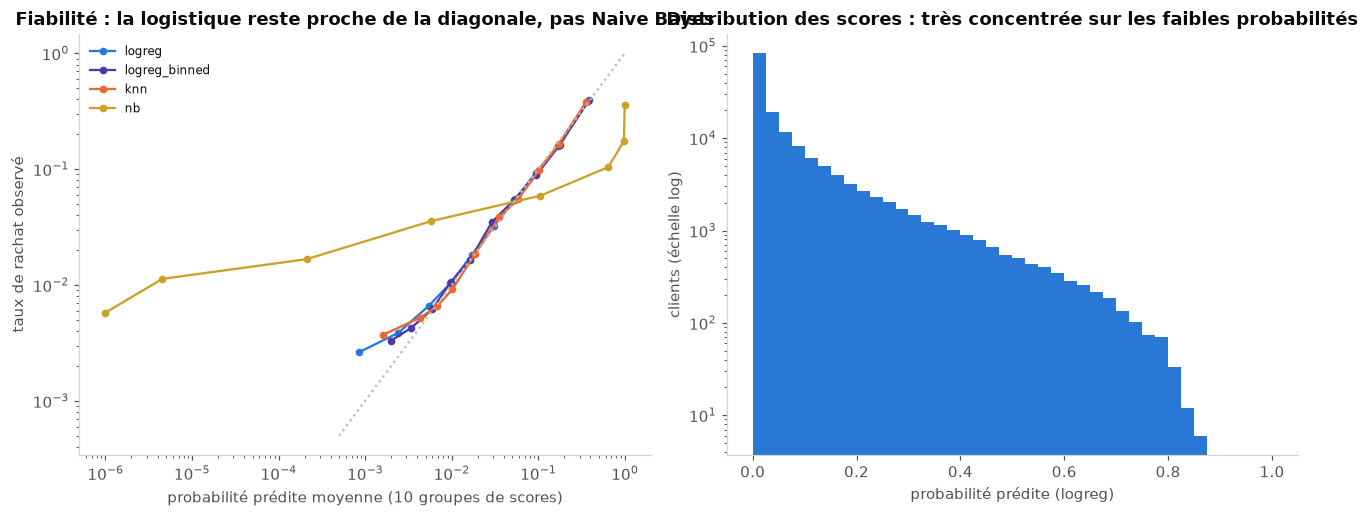

**Lecture.** Moyenne des probabilités prédites par `logreg` : 7,72 %, taux observé 7,72 % ; dans le décile le mieux classé, 38,7 % prédits contre 39,1 % observés. La régression logistique est donc bien calibrée sur la plage utile (log-loss 0,195), contrairement à Naive Bayes (1,105). Réserve (brief) : la cible étant plus étroite que « acheter dans le mois », ces probabilités sont des probabilités de rachat *dans cette définition*, pas des taux mensuels.

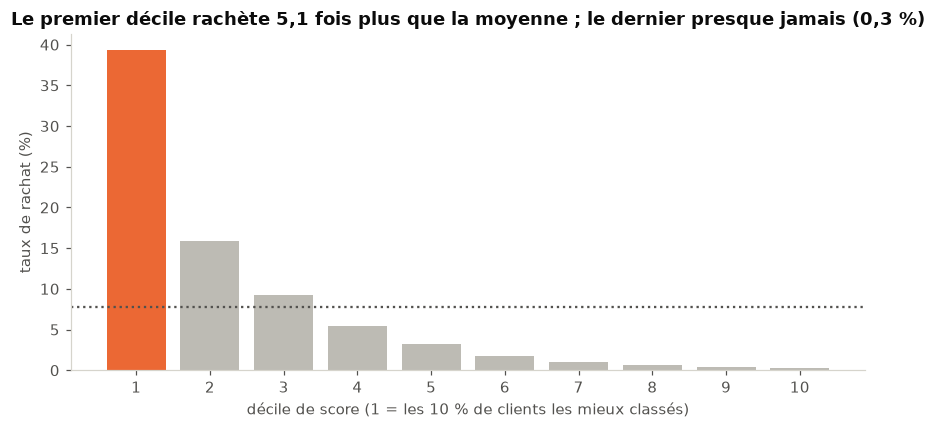

,clients,racheteurs,taux,lift,part des racheteurs
decile,,,,,
1,16043,6308,0.3932,5.0902,0.5090
2,16042,2542,0.1585,2.0514,0.2051
3,16042,1480,0.0923,1.1943,0.1194
4,16043,880,0.0549,0.7101,0.0710
5,16042,523,0.0326,0.4221,0.0422
6,16042,289,0.0180,0.2332,0.0233
7,16043,166,0.0103,0.1340,0.0134
8,16042,98,0.0061,0.0791,0.0079
9,16042,64,0.0040,0.0516,0.0052


In [20]:
# --- calibration (courbe de fiabilité) de la logistique
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
cal_models = [('logreg', c.BLUE), ('logreg_binned', c.PURPLE), ('knn', c.ACCENT), ('nb', '#c9a227')]
for m, col in cal_models:
    fp_, mp_ = calibration_curve(y, OOF[m].clip(1e-6, 1 - 1e-6), n_bins=10, strategy='quantile')
    ax[0].plot(mp_, fp_, 'o-', color=col, label=m, ms=4)
lim = [5e-4, 1]; ax[0].plot(lim, lim, color=c.GREY, ls=':'); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('probabilité prédite moyenne (10 groupes de scores)'); ax[0].set_ylabel('taux de rachat observé'); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title('Fiabilité : la logistique reste proche de la diagonale, pas Naive Bayes')
ax[1].hist(OOF['logreg'], bins=np.linspace(0, 1, 41), color=c.BLUE); ax[1].set_yscale('log'); ax[1].set_xlabel('probabilité prédite (logreg)'); ax[1].set_ylabel('clients (échelle log)')
ax[1].set_title('Distribution des scores : très concentrée sur les faibles probabilités')
fig.tight_layout(); c.save_fig(fig, '03_calibration'); plt.show()
fp_, mp_ = calibration_curve(y, OOF['logreg'], n_bins=10, strategy='quantile')
say(f"**Lecture.** Moyenne des probabilités prédites par `logreg` : {pc(OOF['logreg'].mean(), 2)}, taux observé {pc(y.mean(), 2)} ; dans le décile le mieux classé, {pc(mp_[-1])} prédits contre {pc(fp_[-1])} observés. "
    f"La régression logistique est donc bien calibrée sur la plage utile (log-loss {fr(table.set_index('model').loc['logreg', 'logloss'], 3)}), contrairement à Naive Bayes ({fr(table.set_index('model').loc['nb', 'logloss'], 3)}). "
    f"Réserve (brief) : la cible étant plus étroite que « acheter dans le mois », ces probabilités sont des probabilités de rachat *dans cette définition*, pas des taux mensuels.")

# --- déciles du meilleur modèle
dec = pd.DataFrame({'s': OOF[BEST], 'y': y}); dec['decile'] = 10 - pd.qcut(dec.s.rank(method='first'), 10, labels=False)
dt = dec.groupby('decile').y.agg(['size', 'sum', 'mean']); dt.columns = ['clients', 'racheteurs', 'taux']; dt['lift'] = dt.taux / y.mean(); dt['part des racheteurs'] = dt.racheteurs / y.sum()
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(dt.index, 100 * dt.taux, color=[c.ACCENT] + [c.GREY] * 9); ax.axhline(100 * y.mean(), color=c.INK2, ls=':')
ax.set_xticks(range(1, 11)); ax.set_xlabel('décile de score (1 = les 10 % de clients les mieux classés)'); ax.set_ylabel('taux de rachat (%)')
ax.set_title(f'Le premier décile rachète {fr(dt.taux.iloc[0] / y.mean(), 1)} fois plus que la moyenne ; le dernier presque jamais ({pc(dt.taux.iloc[-1])})')
fig.tight_layout(); c.save_fig(fig, '03_deciles'); plt.show(); display(dt.round(4))

## 8. Sauvegarde des prédictions et soumission du meilleur modèle

Chaque modèle a été enregistré avec `c.save_predictions(nom, oof, test)` au moment de son évaluation (scores hors-échantillon du train ; test = moyenne des 5 modèles de plis). On vérifie la relecture et on écrit la soumission **du meilleur modèle de ce notebook uniquement**, sans l'envoyer à Kaggle.

In [21]:
chk = []
for m in table.model:
    o, t = c.load_predictions(m)
    assert o.index.equals(X.index) and t.index.equals(Xte.index) and o.notna().all() and t.notna().all()
    chk.append({'modèle': m, 'AUC relue': roc_auc_score(y, o), 'moyenne score test': t.mean(), 'moyenne score oof': o.mean()})
chk = pd.DataFrame(chk).set_index('modèle'); display(chk.round(4))
assert np.allclose(chk['AUC relue'].values, table.set_index('model').loc[chk.index, 'auc'].values)
p_sub = c.write_submission(TEST[BEST], f'03_best_{BEST}')
sub = pd.read_csv(p_sub); say(f"Soumission écrite : `submissions/{p_sub.name}` ({fr(len(sub), 0)} lignes, colonnes {list(sub.columns)}, scores dans [{fr(sub.Expected.min(), 4)} ; {fr(sub.Expected.max(), 4)}]). **Non envoyée à Kaggle.**")

,AUC relue,moyenne score test,moyenne score oof
modèle,,,
logreg_lasso,0.8714,0.0775,0.0772
logreg_enet,0.8713,0.0775,0.0772
logreg_ridge,0.8712,0.0776,0.0772
logreg,0.8711,0.0776,0.0772
logreg_lasso_1se,0.8708,0.0774,0.0772
logreg_binned,0.8695,0.0779,0.0773
tree,0.8640,0.0774,0.0773
knn,0.8633,0.0763,0.0761
nb,0.8594,0.2749,0.2733


Soumission écrite : `submissions/03_best_logreg_lasso.csv` (40 106 lignes, colonnes ['ID', 'Expected'], scores dans [0,0003 ; 0,8863]). **Non envoyée à Kaggle.**

## 9. Limites et pistes d'amélioration

In [22]:
s02 = (c.RES / '02_summary.md').read_text()
lgb = float(re.search(r'LightGBM de contrôle.*?AUC (?:\*\*)?(0\.\d+)', s02).group(1)); lgb_lift = re.search(r'LightGBM de contrôle.*?lift (\d+[\.,]\d+)', s02).group(1)
say(f"""- **Plafond des modèles simples.** Le meilleur modèle de ce notebook (`{BEST}`) atteint {fr(best.auc, 3)} d'AUC ; le LightGBM de contrôle du notebook 02, sans aucun réglage, atteignait **{fr(lgb, 3)}** (lift {lgb_lift.replace('.', ',')}). L'écart vient de ce que les modèles linéaires ne capturent pas : **non-linéarités** (l'effet d'un jour de récence n'est pas le même à 3 jours et à 90 jours), **interactions** (récent *et* fréquent vaut plus que la somme des deux effets : cf. grille RFM du notebook 02), effets de seuil. Les variables discrétisées ({fr(gain_bin, 4)} d'AUC par rapport à la logistique Ridge) ne comblent pas l'écart : les effets non linéaires *par variable* ne suffisent pas, l'écart restant viendrait plutôt des **interactions entre variables** (hypothèse que le notebook 04 testera).
- **Arbre.** Lisible mais instable (un autre échantillon donnerait un autre arbre), score à paliers, sur-apprentissage dès que la profondeur croît : c'est le motif des **forêts aléatoires et du boosting** (notebook 04), qui agrègent des centaines d'arbres.
- **Colinéarité.** Les fenêtres de comptage (7, 14, 30, 60, 180 jours, total) sont très corrélées : les odds ratios individuels sont fragiles, seul leur effet joint est robuste. Ridge/Lasso stabilisent la prédiction, pas l'interprétation.
- **k-NN et Naive Bayes** : sans interprétation, dépendants du choix des variables (fait ici *a priori*) ; la dimension ne les pénalise pas ici, mais le ferait avec des variables moins redondantes ; sans gain sur la logistique ; SVM non essayé (coût).
- **Réglage.** Les hyperparamètres sont choisis sur un sous-échantillon de 40 000 clients tiré du train, dont des clients se retrouvent ensuite en validation : léger optimisme sur les AUC rapportées (négligeable devant l'écart-type entre plis, et les AUC sont plates autour de l'optimum). Plis aléatoires, une seule coupure temporelle : on ne mesure pas la dérive dans le temps.
- **Cible étroite.** Le taux de 7,7 % correspond à environ 1,9 jour d'activité : les probabilités ne sont pas des taux mensuels ; seul le classement est fiable.
- **Pistes (notebook 04 puis phase d'optimisation).** Forêt aléatoire, XGBoost, LightGBM réglés par grid/random search ; interactions explicites (récence × fréquence) et splines pour la logistique ; données ouvertes (revenus INSEE par commune) ; suivi de la dérive et ré-entraînement (slide 76).""")

- **Plafond des modèles simples.** Le meilleur modèle de ce notebook (`logreg_lasso`) atteint 0,871 d'AUC ; le LightGBM de contrôle du notebook 02, sans aucun réglage, atteignait **0,877** (lift 5,23). L'écart vient de ce que les modèles linéaires ne capturent pas : **non-linéarités** (l'effet d'un jour de récence n'est pas le même à 3 jours et à 90 jours), **interactions** (récent *et* fréquent vaut plus que la somme des deux effets : cf. grille RFM du notebook 02), effets de seuil. Les variables discrétisées (-0,0017 d'AUC par rapport à la logistique Ridge) ne comblent pas l'écart : les effets non linéaires *par variable* ne suffisent pas, l'écart restant viendrait plutôt des **interactions entre variables** (hypothèse que le notebook 04 testera).
- **Arbre.** Lisible mais instable (un autre échantillon donnerait un autre arbre), score à paliers, sur-apprentissage dès que la profondeur croît : c'est le motif des **forêts aléatoires et du boosting** (notebook 04), qui agrègent des centaines d'arbres.
- **Colinéarité.** Les fenêtres de comptage (7, 14, 30, 60, 180 jours, total) sont très corrélées : les odds ratios individuels sont fragiles, seul leur effet joint est robuste. Ridge/Lasso stabilisent la prédiction, pas l'interprétation.
- **k-NN et Naive Bayes** : sans interprétation, dépendants du choix des variables (fait ici *a priori*) ; la dimension ne les pénalise pas ici, mais le ferait avec des variables moins redondantes ; sans gain sur la logistique ; SVM non essayé (coût).
- **Réglage.** Les hyperparamètres sont choisis sur un sous-échantillon de 40 000 clients tiré du train, dont des clients se retrouvent ensuite en validation : léger optimisme sur les AUC rapportées (négligeable devant l'écart-type entre plis, et les AUC sont plates autour de l'optimum). Plis aléatoires, une seule coupure temporelle : on ne mesure pas la dérive dans le temps.
- **Cible étroite.** Le taux de 7,7 % correspond à environ 1,9 jour d'activité : les probabilités ne sont pas des taux mensuels ; seul le classement est fiable.
- **Pistes (notebook 04 puis phase d'optimisation).** Forêt aléatoire, XGBoost, LightGBM réglés par grid/random search ; interactions explicites (récence × fréquence) et splines pour la logistique ; données ouvertes (revenus INSEE par commune) ; suivi de la dérive et ré-entraînement (slide 76).

## 10. Résumé écrit (`results/03_summary.md`)

In [23]:
tb = table.set_index('model')
def line(m): r = tb.loc[m]; return f"| `{m}` | {r.auc:.4f} | {r.auc_fold_std:.4f} | {'-' if pd.isna(r.logloss) else f'{r.logloss:.4f}'} | {100 * r.precision_top10:.1f} % | {100 * r.recall_top10:.1f} % | {r.lift_top10:.2f} |"
top_or = odds.head(5)
md_lines = [
 "# Résumé du notebook 03 : modèles de référence (règle, logistique, arbre, k-NN, Naive Bayes)", "",
 "## Chiffres clés (CV 5 plis communs, scores hors-échantillon ; top 10 % = 10 % des clients les mieux classés)",
 f"- **Meilleur modèle du notebook : `{BEST}`**, AUC {best.auc:.4f} (écart-type entre plis {best.auc_fold_std:.4f}), top 10 % : précision {100 * best.precision_top10:.1f} %, rappel {100 * best.recall_top10:.1f} %, lift {best.lift_top10:.2f}.",
 f"- Référence à battre : récence seule AUC {rec.auc:.4f}, précision {100 * rec.precision_top10:.1f} %, lift {rec.lift_top10:.2f} ; LightGBM de contrôle (notebook 02, non réglé) AUC {lgb:.4f}.",
 f"- Les {len(table[table.model.str.startswith('logreg')])} variantes logistiques sont à {table[table.model.str.startswith('logreg')].auc.max() - table[table.model.str.startswith('logreg')].auc.min():.4f} d'AUC l'une de l'autre : le choix se fait sur l'interprétabilité.",
 f"- Lasso parcimonieux : {nz(m_1se):.0f} coefficients non nuls sur {ptot} (meilleur AUC : {nz(m_lasso):.0f}).", "",
 "| modèle | AUC | écart-type plis | log-loss | précision top 10 % | rappel top 10 % | lift |", "|---|---|---|---|---|---|---|",
 *[line(m) for m in table.model], "",
 "## Figures (message)",
 "- `figures/03_reglage_penalises.png` : l'AUC est quasi plate autour de l'optimum de C : le réglage de la pénalité compte peu.",
 f"- `figures/03_lasso_chemin.png` : à la pénalité maximale, {len(first_vars)} variables survivent ({', '.join(first_vars[:4])}…) ; le nombre de variables retenues croît avec C.",
 "- `figures/03_odds_ratios.png` : odds ratios (avec IC 95 %) des 20 variables les plus influentes du modèle parcimonieux.",
 "- `figures/03_arbre_surapprentissage.png` : sans garde-fou la validation retombe quand la profondeur croît ; la taille de feuille stabilise.",
 f"- `figures/03_arbre_lisible.png` : un arbre à 3 niveaux = {len(rules)} règles de segmentation du rachat.",
 "- `figures/03_knn_k.png` : le k optimal du k-NN grandit avec la taille de l'échantillon.",
 "- `figures/03_auc_par_pli.png` : AUC par pli, très stable ; l'écart entre familles dépasse l'écart entre plis.",
 "- `figures/03_roc_gain.png` : ROC et gain cumulé : part des racheteurs captés en ciblant 10 % de la base.",
 "- `figures/03_matrice_confusion.png` : matrice de confusion au seuil du top 10 % (meilleur modèle vs récence).",
 "- `figures/03_calibration.png` : la logistique est bien calibrée, Naive Bayes ne l'est pas.",
 "- `figures/03_deciles.png` : taux de rachat par décile de score du meilleur modèle.", "",
 "## Décisions méthodologiques",
 f"- Linéaires : jumeau log à la place de l'original (AUC +{d_log:.4f} vs brut), médiane + standardisation, one-hot N-1 (référence = modalité la plus fréquente). Arbres : variables brutes, NaN natifs.",
 "- Hyperparamètres : grid search (Ridge, Lasso, binned, arbre, k-NN, Naive Bayes) et random search (ElasticNet) sur 40 000 clients stratifiés, 5 plis, critère AUC ; puis CV complète. Règle de l'écart-type pour le Lasso parcimonieux.",
 f"- Variables discrétisées : {NB_BEST} classes de quantiles + Ridge (C={C_BIN:.3g}). k-NN : 8 variables choisies a priori (R, F, M, rythme), k={K_BEST} réglé à pleine taille. SVM non entraîné (coût sur 160 000 lignes).",
 "- Prédiction du test = moyenne des 5 modèles de plis. Soumission du meilleur : `submissions/03_best_" + BEST + ".csv` (non envoyée à Kaggle).", "",
 "## Anomalies et points de vigilance",
 f"- Le notebook 02 annonçait 31 jumeaux log et 49 colonnes à NaN ; la table enregistrée en contient {len(LOG)} et {n_na}.",
 f"- Récence et RFM : peu de valeurs distinctes, beaucoup d'ex-aequo à la coupure du top 10 % (départage par l'ordre des identifiants).",
 f"- Odds ratios : corrélation maximale {cmv.max():.2f} entre variables de comptage retenues : lecture conjointe obligatoire.", "",
 "## Limites et pistes",
 f"- Plafond linéaire : LightGBM non réglé à {lgb:.3f} d'AUC contre {best.auc:.3f} ici : non-linéarités et interactions (notebook 04).",
 "- Réglage sur un sous-échantillon du train (léger optimisme) ; plis aléatoires, une seule coupure ; cible plus étroite que « acheter dans le mois ».",
 "- Pistes : forêt aléatoire, XGBoost, LightGBM réglés ; interactions et splines pour la logistique ; données ouvertes ; suivi de la dérive.",
]
assert len(md_lines) <= 60, len(md_lines)
(c.RES / '03_summary.md').write_text('\n'.join(md_lines) + '\n')
say(f"`results/03_summary.md` écrit ({len(md_lines)} lignes). Fichiers produits : `results/03_model_comparison.csv`, `results/03_odds_ratios.csv`, figures `03_*.png`, prédictions dans `c.WORK/preds`.")

`results/03_summary.md` écrit (51 lignes). Fichiers produits : `results/03_model_comparison.csv`, `results/03_odds_ratios.csv`, figures `03_*.png`, prédictions dans `c.WORK/preds`.